# 08 · SQL Business Analytics & Database Integration
**Customer Revenue Intelligence**, Step 10

> ⚠️ **SYNTHETIC DATA.** The database `data/customer_revenue_intelligence.db` (SQLite) holds the cleaned transactions (Step 3) and the RFM, cluster, CLV and forecast outputs (Steps 5–9).

**Rule for this notebook:** every business number is calculated **by SQL**. Python only:
- connects to the database;
- runs the SQL text stored in `sql/analysis_queries.sql` and `sql/business_queries.sql`;
- displays the results and draws charts from them.

In [1]:
import sys, sqlite3, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd
from IPython.display import Image, Markdown, display
import config
from src import sql_analytics as sa

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
FIG = sa.FIG_DIR

# Build + validate the database, run every query, save tables / figures / report (fully reproducible)
R = sa.run_sql_workflow(make_plots=True, verbose=True)

# Helper: print the SQL of a named query, then execute it live against the database
QUERIES = {b["name"]: b for f in (sa.ANALYSIS_FILE, sa.BUSINESS_FILE) for b in sa.parse_sql_file(f)}
con = sqlite3.connect(config.DATABASE_FILE)

def show(name, rows=15):
    b = QUERIES[name]
    head = b.get("title") or b.get("question")
    display(Markdown(f"**{name}** - {head}\n\n```sql\n{b['sql']}\n```"))
    df = pd.read_sql_query(b["sql"], con)
    display(df.head(rows))
    return df

Database: data/customer_revenue_intelligence.db | validation 56/56 | queries 57 | figures 12 | QC 20/20


## 1. Connect to the database: tables, keys and relationships

In [2]:
print("SQLite", sqlite3.sqlite_version, "|", config.DATABASE_FILE.relative_to(config.PROJECT_ROOT))
R["tables"][["Table", "Layer", "Rows", "Columns", "Primary_Key", "Foreign_Keys"]]

SQLite 3.45.1 | data/customer_revenue_intelligence.db


,Table,Layer,Rows,Columns,Primary_Key,Foreign_Keys
0,locations,Transactional,35,4,location_id,-
1,customers,Transactional,2000,5,customer_id,location_id -> locations.location_id
2,products,Transactional,61,4,product_id,-
3,orders,Transactional,13251,5,order_id,customer_id -> customers.customer_id
4,order_items,Transactional,18670,10,order_line_id,product_id -> products.product_id; order_id -> orders.order_id
5,rfm_segment_definitions,Analytics,11,5,segment_name,-
6,customer_rfm,Analytics,1984,15,customer_id,rfm_segment -> rfm_segment_definitions.segment_name; customer_id -> customers.customer_id
7,ml_clusters,Analytics,4,3,cluster_id,-
8,customer_segments,Analytics,1984,5,customer_id,cluster_id -> ml_clusters.cluster_id; customer_id -> customers.customer_id
9,customer_value,Analytics,1984,12,customer_id,customer_id -> customers.customer_id


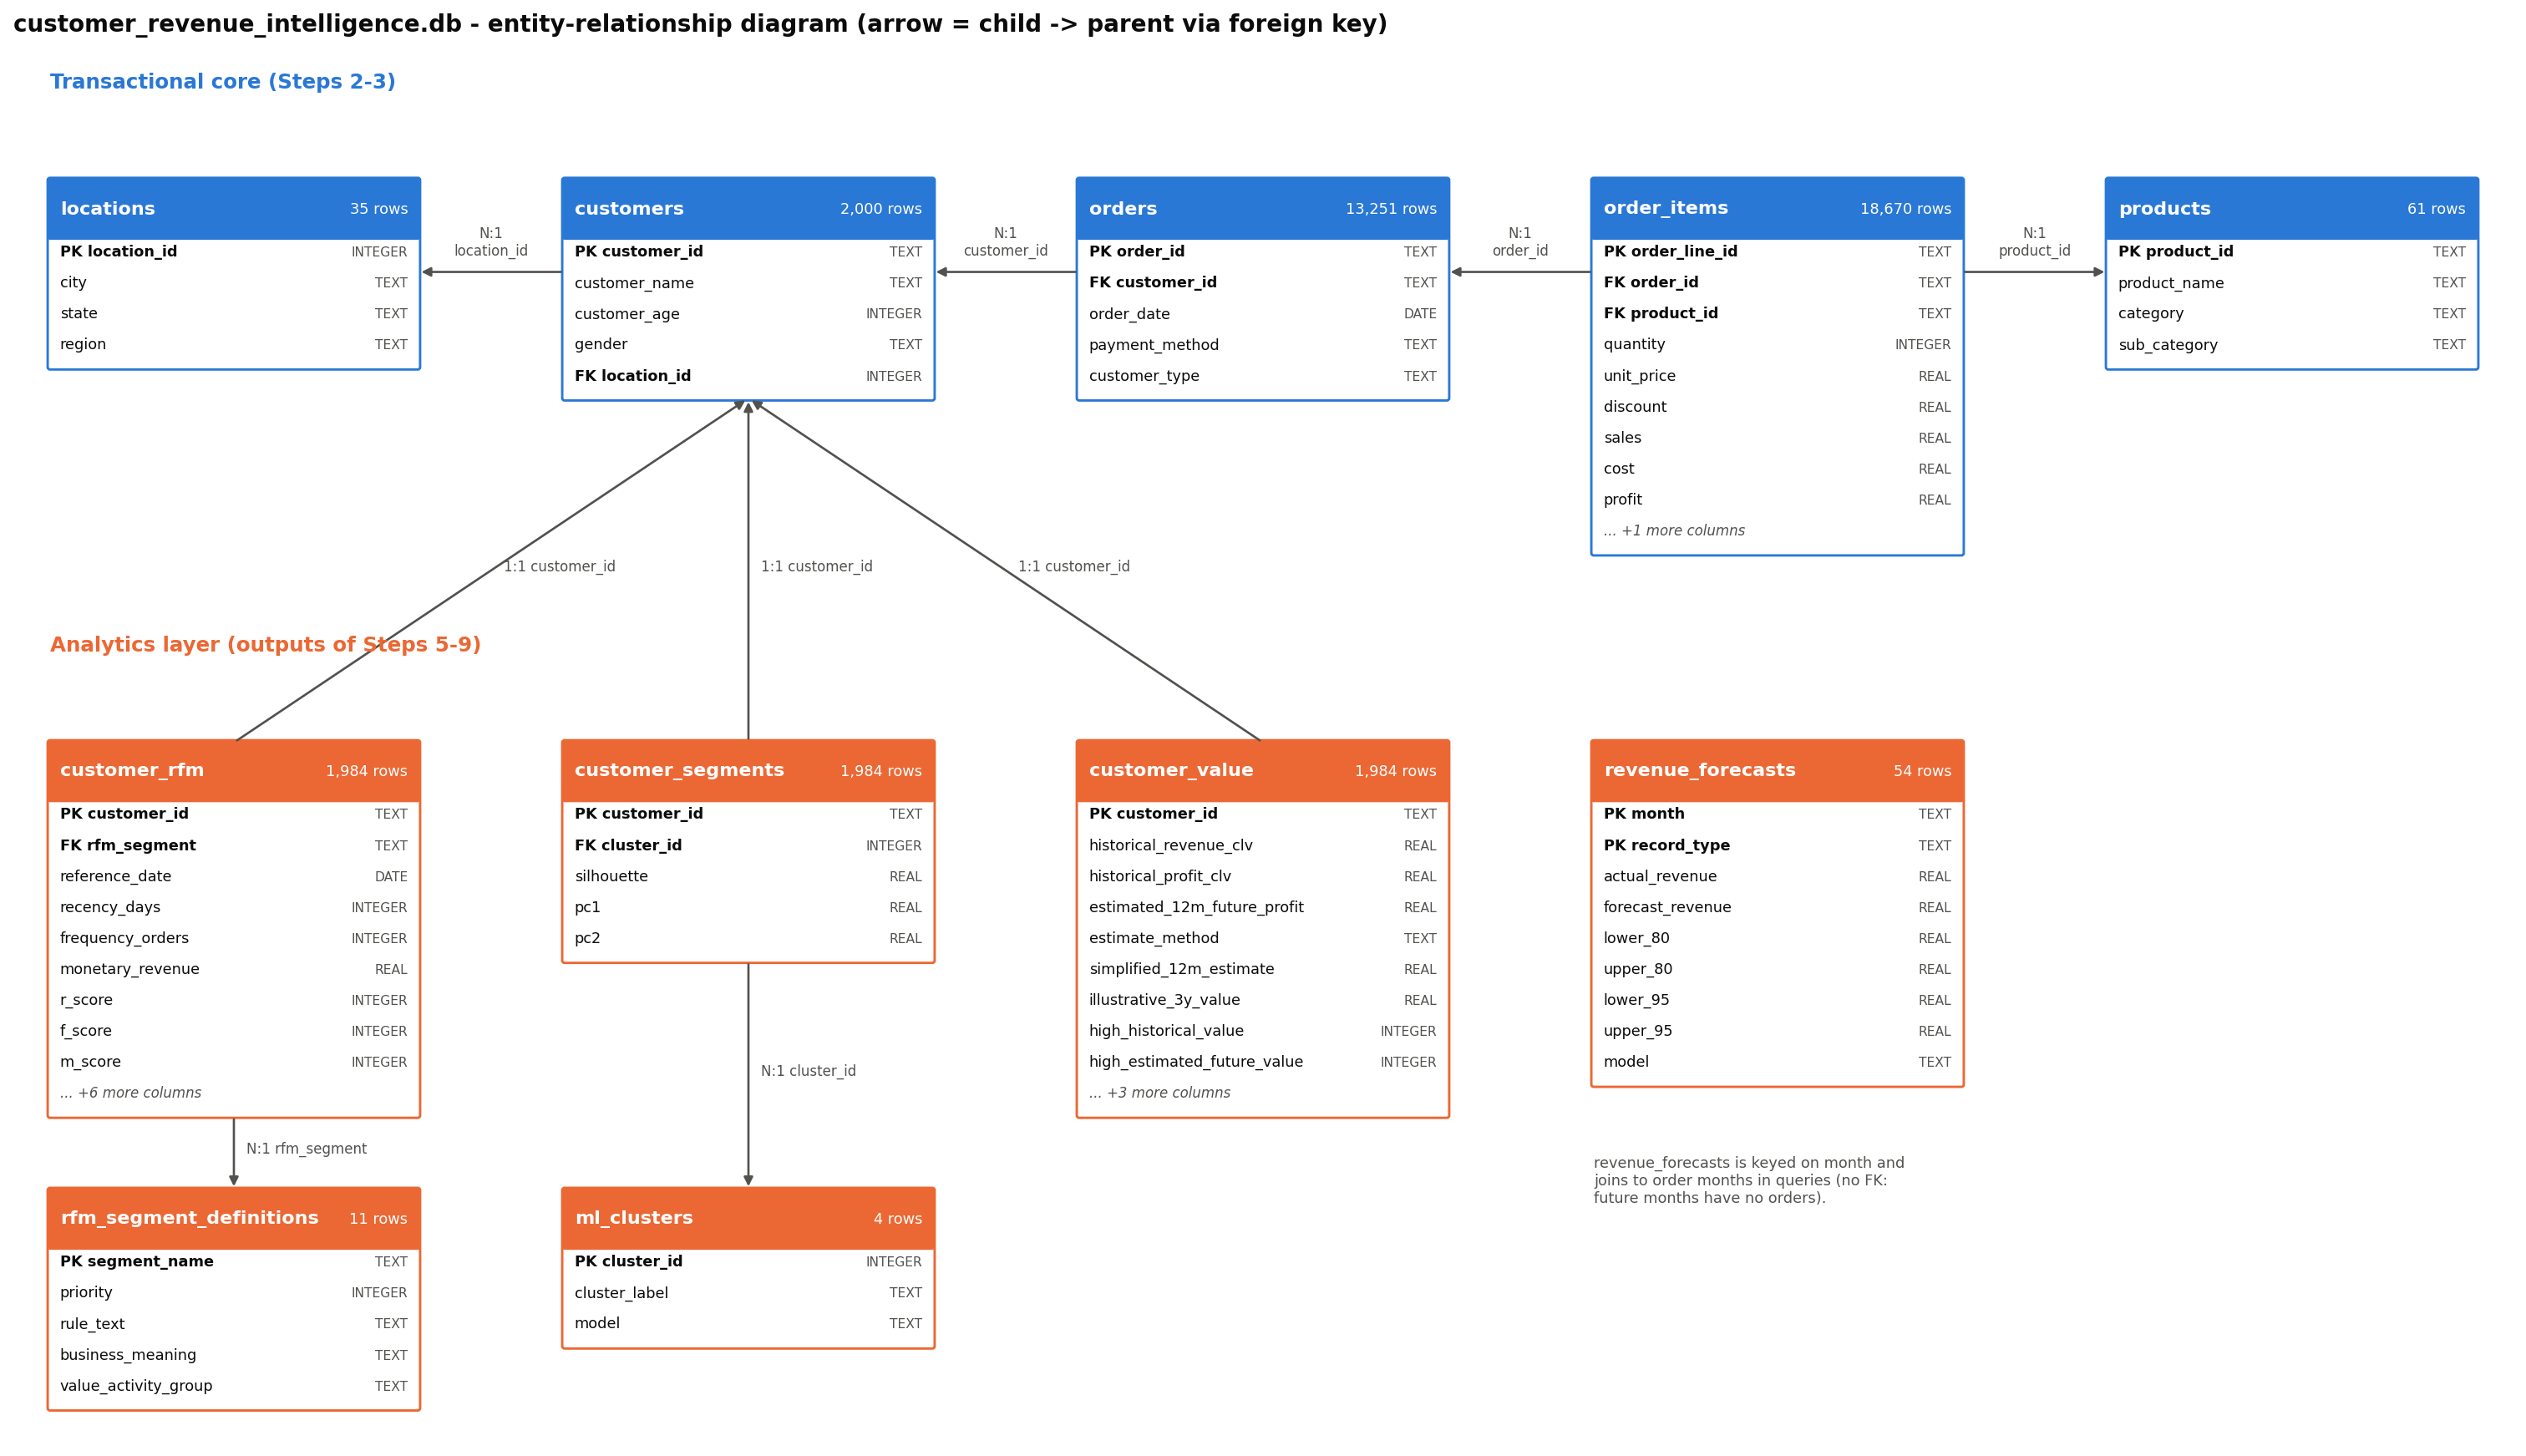

In [3]:
Image(str(FIG / "er_diagram.png"))

- **Transactional core:** `locations → customers → orders → order_items ← products`.
- **Analytics layer:** holds only what the Python steps produced, keyed on `customer_id` (RFM scores, clusters, CLV) or on month (forecasts).
- **Revenue rule:** Delivered lines only. It is defined once, in the view `vw_delivered_sales`.

## 2. Validate the database against the source data

In [4]:
R['validation']

,Area,Check,SQL,Python / source,Pass
0,Row counts,locations rows,35,35,True
1,Row counts,customers rows,2000,2000,True
2,Row counts,products rows,61,61,True
3,Row counts,orders rows,13251,13251,True
4,Row counts,order_items rows,18670,18670,True
5,Row counts,rfm_segment_definitions rows,11,11,True
6,Row counts,customer_rfm rows,1984,1984,True
7,Row counts,ml_clusters rows,4,4,True
8,Row counts,customer_segments rows,1984,1984,True
9,Row counts,customer_value rows,1984,1984,True


- **Checks passed:** all 56.
- **What they cover:**
  - row counts;
  - unique customers and products;
  - revenue, profit, cost, quantity and orders, compared with totals pandas computes independently from the cleaned CSV;
  - NULLs, duplicate primary keys and orphan foreign keys;
  - cross-step consistency: SQL recomputations match the Step 5 RFM values, Step 6 cluster revenue, Step 7 CLV profit and Step 9 monthly actuals.

## 3. Revenue analysis

In [5]:
show("rev_kpi_summary", 15)

**rev_kpi_summary** - Headline KPIs - total revenue, profit, margin, orders, customers, AOV

```sql
SELECT
    ROUND(SUM(sales), 2)                                   AS total_revenue,
    ROUND(SUM(cost), 2)                                    AS total_cost,
    ROUND(SUM(profit), 2)                                  AS total_profit,
    ROUND(100.0 * SUM(profit) / SUM(sales), 2)             AS profit_margin_pct,
    COUNT(DISTINCT order_id)                               AS total_orders,
    COUNT(DISTINCT customer_id)                            AS total_customers,
    ROUND(SUM(sales) / COUNT(DISTINCT order_id), 2)        AS average_order_value,
    COUNT(*)                                               AS order_lines,
    SUM(quantity)                                          AS units_sold,
    MIN(order_date)                                        AS first_order_date,
    MAX(order_date)                                        AS last_order_date
FROM vw_delivered_sales;
```

,total_revenue,total_cost,total_profit,profit_margin_pct,total_orders,total_customers,average_order_value,order_lines,units_sold,first_order_date,last_order_date
0,"60,056,569.15","46,034,017.57","14,022,551.58",23.35,12212,1984,"4,917.83",16860,22772,2023-01-01,2025-12-31


,total_revenue,total_cost,total_profit,profit_margin_pct,total_orders,total_customers,average_order_value,order_lines,units_sold,first_order_date,last_order_date
0,"60,056,569.15","46,034,017.57","14,022,551.58",23.35,12212,1984,"4,917.83",16860,22772,2023-01-01,2025-12-31


In [6]:
show("rev_by_year", 15)

**rev_by_year** - Revenue, profit and margin by year with year-over-year growth

```sql
WITH yearly AS (
    SELECT order_year,
           SUM(sales)               AS revenue,
           SUM(profit)              AS profit,
           COUNT(DISTINCT order_id) AS orders,
           COUNT(DISTINCT customer_id) AS customers
    FROM vw_delivered_sales
    GROUP BY order_year
)
SELECT order_year,
       ROUND(revenue, 2)                                              AS revenue,
       ROUND(profit, 2)                                               AS profit,
       ROUND(100.0 * profit / revenue, 2)                             AS profit_margin_pct,
       orders, customers,
       ROUND(revenue / orders, 2)                                     AS average_order_value,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY order_year))
             / LAG(revenue) OVER (ORDER BY order_year), 2)            AS revenue_yoy_growth_pct,
       ROUND(100.0 * (profit - LAG(profit) OVER (ORDER BY order_year))
             / LAG(profit) OVER (ORDER BY order_year), 2)             AS profit_yoy_growth_pct
FROM yearly
ORDER BY order_year;
```

,order_year,revenue,profit,profit_margin_pct,orders,customers,average_order_value,revenue_yoy_growth_pct,profit_yoy_growth_pct
0,2023,"13,060,877.25","2,957,857.43",22.65,2811,1137,"4,646.35",NaN,NaN
1,2024,"19,769,754.90","4,557,848.19",23.05,4014,1328,"4,925.20",51.37,54.09
2,2025,"27,225,937.00","6,506,845.96",23.90,5387,1716,"5,054.01",37.72,42.76


,order_year,revenue,profit,profit_margin_pct,orders,customers,average_order_value,revenue_yoy_growth_pct,profit_yoy_growth_pct
0,2023,"13,060,877.25","2,957,857.43",22.65,2811,1137,"4,646.35",NaN,NaN
1,2024,"19,769,754.90","4,557,848.19",23.05,4014,1328,"4,925.20",51.37,54.09
2,2025,"27,225,937.00","6,506,845.96",23.90,5387,1716,"5,054.01",37.72,42.76


In [7]:
show("rev_order_status", 15)

**rev_order_status** - Order lines and booked value by status (why only Delivered lines count as revenue)

```sql
SELECT
    order_status,
    COUNT(*)                                               AS order_lines,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)     AS pct_of_lines,
    ROUND(SUM(quantity * unit_price * (1 - discount)), 2)  AS booked_value
FROM order_items
GROUP BY order_status
ORDER BY order_lines DESC;
```

,order_status,order_lines,pct_of_lines,booked_value
0,Delivered,16860,90.31,"60,056,569.15"
1,Returned,1101,5.90,"3,511,838.90"
2,Cancelled,709,3.80,"2,743,594.30"


,order_status,order_lines,pct_of_lines,booked_value
0,Delivered,16860,90.31,"60,056,569.15"
1,Returned,1101,5.90,"3,511,838.90"
2,Cancelled,709,3.80,"2,743,594.30"


- **Growth:** revenue grew 51% in 2024 and 38% in 2025, and the profit margin edged up each year.
- **Excluded revenue:** Returned and Cancelled lines (10% of lines) are left out of revenue by design.

## 4. Customer analytics

In [8]:
show("cust_top_revenue", 10)

**cust_top_revenue** - Top 20 customers by revenue (with rank and share of total)

```sql
WITH c AS (
    SELECT customer_id, SUM(sales) AS revenue, SUM(profit) AS profit, COUNT(DISTINCT order_id) AS orders
    FROM vw_delivered_sales
    GROUP BY customer_id
)
SELECT RANK() OVER (ORDER BY revenue DESC)                      AS revenue_rank,
       customer_id,
       ROUND(revenue, 2) AS revenue, ROUND(profit, 2) AS profit, orders,
       ROUND(revenue / orders, 2)                                AS average_order_value,
       ROUND(100.0 * revenue / SUM(revenue) OVER (), 3)          AS pct_of_total_revenue
FROM c
ORDER BY revenue DESC
LIMIT 20;
```

,revenue_rank,customer_id,revenue,profit,orders,average_order_value,pct_of_total_revenue
0,1,CUST-1128,"417,800.45","51,829.47",27,"15,474.09",0.70
1,2,CUST-1724,"400,151.70","67,098.23",28,"14,291.13",0.67
2,3,CUST-0669,"314,818.65","36,558.33",16,"19,676.17",0.52
3,4,CUST-0908,"307,090.05","58,919.91",26,"11,811.16",0.51
4,5,CUST-1172,"272,866.60","45,823.36",25,"10,914.66",0.45
5,6,CUST-0941,"263,670.35","50,340.99",27,"9,765.57",0.44
6,7,CUST-1969,"261,877.00","42,321.90",25,"10,475.08",0.44
7,8,CUST-1044,"258,231.30","39,819.88",29,"8,904.53",0.43
8,9,CUST-1416,"255,399.20","26,676.39",22,"11,609.05",0.42
9,10,CUST-1489,"255,128.00","49,175.91",28,"9,111.71",0.42


,revenue_rank,customer_id,revenue,profit,orders,average_order_value,pct_of_total_revenue
0,1,CUST-1128,"417,800.45","51,829.47",27,"15,474.09",0.70
1,2,CUST-1724,"400,151.70","67,098.23",28,"14,291.13",0.67
2,3,CUST-0669,"314,818.65","36,558.33",16,"19,676.17",0.52
3,4,CUST-0908,"307,090.05","58,919.91",26,"11,811.16",0.51
4,5,CUST-1172,"272,866.60","45,823.36",25,"10,914.66",0.45
5,6,CUST-0941,"263,670.35","50,340.99",27,"9,765.57",0.44
6,7,CUST-1969,"261,877.00","42,321.90",25,"10,475.08",0.44
7,8,CUST-1044,"258,231.30","39,819.88",29,"8,904.53",0.43
8,9,CUST-1416,"255,399.20","26,676.39",22,"11,609.05",0.42
9,10,CUST-1489,"255,128.00","49,175.91",28,"9,111.71",0.42


In [9]:
show("cust_new_vs_existing", 15)

**cust_new_vs_existing** - New vs existing customers (customer type on each customer's first order)

```sql
WITH first_order AS (
    SELECT customer_id, customer_type,
           ROW_NUMBER() OVER (PARTITION BY customer_id ORDER BY order_date, order_id) AS rn
    FROM orders
),
cust AS (
    SELECT f.customer_id,
           CASE f.customer_type WHEN 'New' THEN 'Acquired 2023-2025' ELSE 'Existing before 2023' END AS acquisition_status
    FROM first_order f
    WHERE f.rn = 1
)
SELECT c.acquisition_status,
       COUNT(DISTINCT c.customer_id)                                   AS customers,
       COUNT(DISTINCT d.customer_id)                                   AS customers_with_delivered_order,
       ROUND(SUM(d.sales), 2)                                          AS revenue,
       ROUND(100.0 * SUM(d.sales) / (SELECT SUM(sales) FROM vw_delivered_sales), 2) AS pct_of_revenue,
       ROUND(SUM(d.sales) / COUNT(DISTINCT d.customer_id), 2)          AS revenue_per_customer,
       ROUND(1.0 * COUNT(DISTINCT d.order_id) / COUNT(DISTINCT d.customer_id), 2) AS orders_per_customer
FROM cust c
LEFT JOIN vw_delivered_sales d ON d.customer_id = c.customer_id
GROUP BY c.acquisition_status;
```

,acquisition_status,customers,customers_with_delivered_order,revenue,pct_of_revenue,revenue_per_customer,orders_per_customer
0,Acquired 2023-2025,1229,1217,"28,270,586.60",47.07,"23,229.73",4.97
1,Existing before 2023,771,767,"31,785,982.55",52.93,"41,441.96",8.03


,acquisition_status,customers,customers_with_delivered_order,revenue,pct_of_revenue,revenue_per_customer,orders_per_customer
0,Acquired 2023-2025,1229,1217,"28,270,586.60",47.07,"23,229.73",4.97
1,Existing before 2023,771,767,"31,785,982.55",52.93,"41,441.96",8.03


In [10]:
show("cust_frequency_distribution", 15)

**cust_frequency_distribution** - Customer purchase frequency distribution (delivered orders per customer)

```sql
WITH c AS (
    SELECT customer_id, COUNT(DISTINCT order_id) AS orders, SUM(sales) AS revenue
    FROM vw_delivered_sales
    GROUP BY customer_id
)
SELECT CASE WHEN orders = 1 THEN '1 order'
            WHEN orders BETWEEN 2 AND 3 THEN '2-3 orders'
            WHEN orders BETWEEN 4 AND 6 THEN '4-6 orders'
            WHEN orders BETWEEN 7 AND 10 THEN '7-10 orders'
            ELSE '11+ orders' END                                      AS frequency_band,
       MIN(orders)                                                     AS band_min,
       COUNT(*)                                                        AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)              AS pct_of_customers,
       ROUND(SUM(revenue), 2)                                          AS revenue,
       ROUND(100.0 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 2)      AS pct_of_revenue
FROM c
GROUP BY frequency_band
ORDER BY band_min;
```

,frequency_band,band_min,customers,pct_of_customers,revenue,pct_of_revenue
0,1 order,1,210,10.58,"843,923.20",1.41
1,2-3 orders,2,588,29.64,"5,637,978.25",9.39
2,4-6 orders,4,526,26.51,"9,777,482.05",16.28
3,7-10 orders,7,339,17.09,"12,498,573.35",20.81
4,11+ orders,11,321,16.18,"31,298,612.30",52.12


,frequency_band,band_min,customers,pct_of_customers,revenue,pct_of_revenue
0,1 order,1,210,10.58,"843,923.20",1.41
1,2-3 orders,2,588,29.64,"5,637,978.25",9.39
2,4-6 orders,4,526,26.51,"9,777,482.05",16.28
3,7-10 orders,7,339,17.09,"12,498,573.35",20.81
4,11+ orders,11,321,16.18,"31,298,612.30",52.12


In [11]:
show("cust_inactive", 15)

**cust_inactive** - Customers with no purchase for >= 90 / 180 / 365 days (inactivity, NOT churn - see Step 7)

```sql
WITH ref AS (SELECT date(MAX(order_date), '+1 day') AS ref_date FROM orders),
last_buy AS (
    SELECT customer_id, MAX(order_date) AS last_order, SUM(sales) AS revenue
    FROM vw_delivered_sales
    GROUP BY customer_id
),
t(days) AS (VALUES (90), (180), (365))
SELECT t.days                                                                     AS inactive_for_at_least_days,
       (SELECT ref_date FROM ref)                                                 AS reference_date,
       SUM(CASE WHEN julianday((SELECT ref_date FROM ref)) - julianday(l.last_order) >= t.days THEN 1 ELSE 0 END) AS customers,
       ROUND(100.0 * SUM(CASE WHEN julianday((SELECT ref_date FROM ref)) - julianday(l.last_order) >= t.days THEN 1 ELSE 0 END)
             / COUNT(*), 2)                                                       AS pct_of_customers,
       ROUND(SUM(CASE WHEN julianday((SELECT ref_date FROM ref)) - julianday(l.last_order) >= t.days
                      THEN l.revenue ELSE 0 END), 2)                               AS their_lifetime_revenue
FROM t CROSS JOIN last_buy l
GROUP BY t.days
ORDER BY t.days;


-- 3. RFM & ML SEGMENTATION (analysing the Python outputs; nothing is re-segmented in SQL)
```

,inactive_for_at_least_days,reference_date,customers,pct_of_customers,their_lifetime_revenue
0,90,2026-01-01,1149,57.91,"20,322,586.40"
1,180,2026-01-01,696,35.08,"11,799,198.65"
2,365,2026-01-01,268,13.51,"2,124,027.50"


,inactive_for_at_least_days,reference_date,customers,pct_of_customers,their_lifetime_revenue
0,90,2026-01-01,1149,57.91,"20,322,586.40"
1,180,2026-01-01,696,35.08,"11,799,198.65"
2,365,2026-01-01,268,13.51,"2,124,027.50"


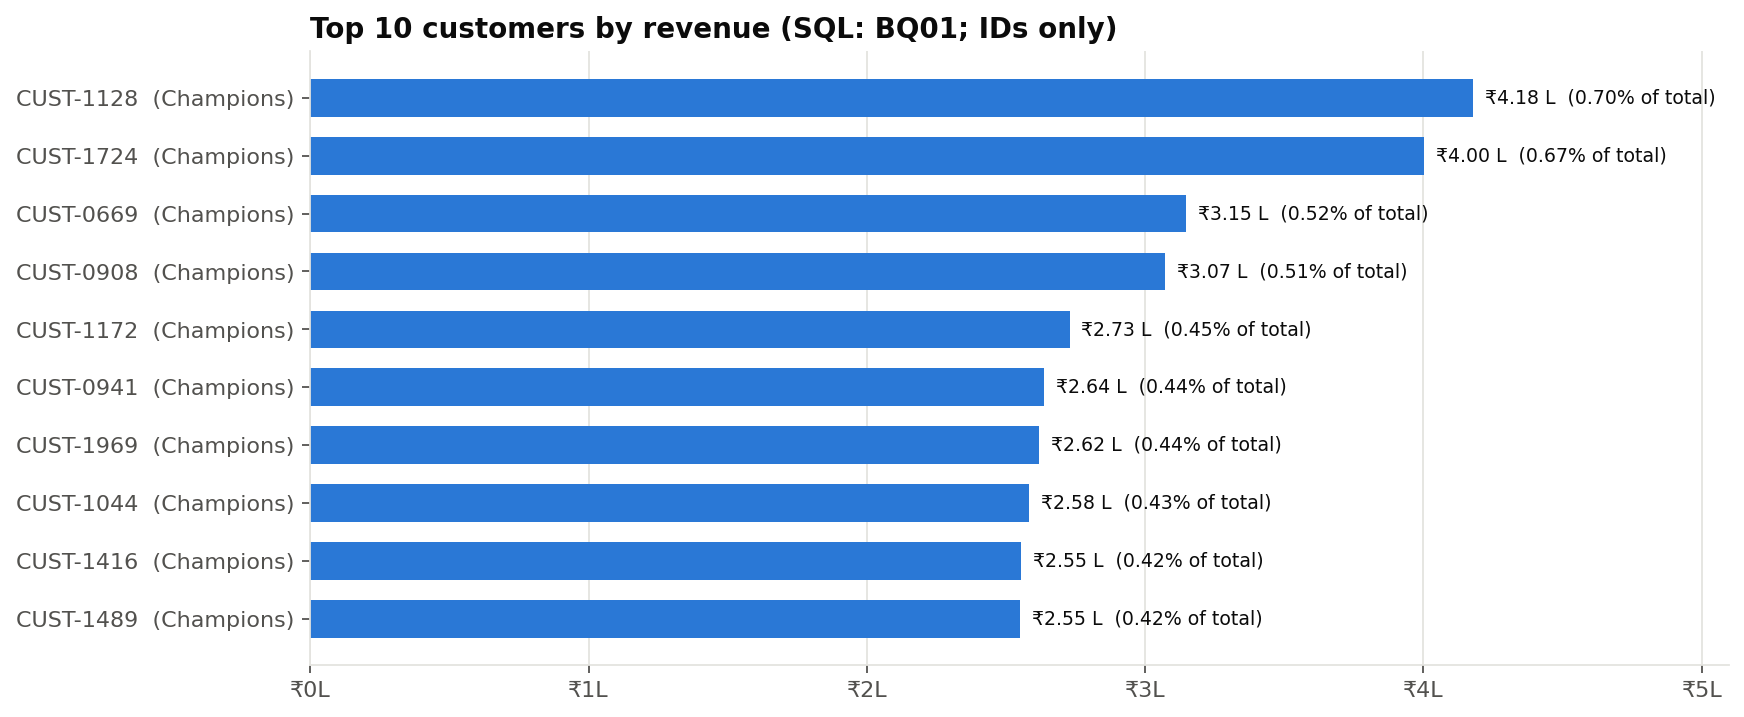

In [12]:
Image(str(FIG / "sql_top10_customers.png"))

- **Repeat buyers:** customers with 11+ orders are 16% of customers but 52% of revenue.
- **Inactivity:** it is measured from a reference date that the SQL computes itself. It is reported as inactivity, **not churn** (see Step 7).

## 5. Revenue contribution analysis (window functions)

In [13]:
show("cust_revenue_concentration", 10)

**cust_revenue_concentration** - Customer revenue concentration - rank, cumulative revenue and cumulative % (Pareto)

```sql
WITH c AS (
    SELECT customer_id, SUM(sales) AS revenue
    FROM vw_delivered_sales
    GROUP BY customer_id
)
SELECT ROW_NUMBER() OVER (ORDER BY revenue DESC, customer_id)                            AS customer_rank,
       customer_id,
       ROUND(revenue, 2)                                                                  AS customer_revenue,
       ROUND(SUM(revenue) OVER (ORDER BY revenue DESC, customer_id ROWS UNBOUNDED PRECEDING), 2) AS cumulative_revenue,
       ROUND(100.0 * revenue / SUM(revenue) OVER (), 4)                                   AS pct_of_total_revenue,
       ROUND(100.0 * SUM(revenue) OVER (ORDER BY revenue DESC, customer_id ROWS UNBOUNDED PRECEDING)
             / SUM(revenue) OVER (), 3)                                                   AS cumulative_pct_of_revenue,
       ROUND(100.0 * ROW_NUMBER() OVER (ORDER BY revenue DESC, customer_id) / COUNT(*) OVER (), 3) AS cumulative_pct_of_customers
FROM c
ORDER BY customer_rank;
```

,customer_rank,customer_id,customer_revenue,cumulative_revenue,pct_of_total_revenue,cumulative_pct_of_revenue,cumulative_pct_of_customers
0,1,CUST-1128,"417,800.45","417,800.45",0.70,0.70,0.05
1,2,CUST-1724,"400,151.70","817,952.15",0.67,1.36,0.10
2,3,CUST-0669,"314,818.65","1,132,770.80",0.52,1.89,0.15
3,4,CUST-0908,"307,090.05","1,439,860.85",0.51,2.40,0.20
4,5,CUST-1172,"272,866.60","1,712,727.45",0.45,2.85,0.25
5,6,CUST-0941,"263,670.35","1,976,397.80",0.44,3.29,0.30
6,7,CUST-1969,"261,877.00","2,238,274.80",0.44,3.73,0.35
7,8,CUST-1044,"258,231.30","2,496,506.10",0.43,4.16,0.40
8,9,CUST-1416,"255,399.20","2,751,905.30",0.43,4.58,0.45
9,10,CUST-1489,"255,128.00","3,007,033.30",0.42,5.01,0.50


,customer_rank,customer_id,customer_revenue,cumulative_revenue,pct_of_total_revenue,cumulative_pct_of_revenue,cumulative_pct_of_customers
0,1,CUST-1128,"417,800.45","417,800.45",0.70,0.70,0.05
1,2,CUST-1724,"400,151.70","817,952.15",0.67,1.36,0.10
2,3,CUST-0669,"314,818.65","1,132,770.80",0.52,1.89,0.15
3,4,CUST-0908,"307,090.05","1,439,860.85",0.51,2.40,0.20
4,5,CUST-1172,"272,866.60","1,712,727.45",0.45,2.85,0.25
...,...,...,...,...,...,...,...
1979,1980,CUST-1175,379.10,"60,055,210.75",0.00,100.00,99.80
1980,1981,CUST-1743,377.25,"60,055,588.00",0.00,100.00,99.85
1981,1982,CUST-0156,376.20,"60,055,964.20",0.00,100.00,99.90
1982,1983,CUST-1058,367.20,"60,056,331.40",0.00,100.00,99.95


In [14]:
show("cust_concentration_summary", 15)

**cust_concentration_summary** - Share of revenue held by the top 1% / 5% / 10% / 20% / 50% of customers

```sql
WITH c AS (
    SELECT customer_id, SUM(sales) AS revenue FROM vw_delivered_sales GROUP BY customer_id
),
r AS (
    SELECT revenue, ROW_NUMBER() OVER (ORDER BY revenue DESC, customer_id) AS rk, COUNT(*) OVER () AS n
    FROM c
),
t(top_pct) AS (VALUES (1), (5), (10), (20), (50))
SELECT t.top_pct,
       CAST(ROUND(MAX(r.n) * t.top_pct / 100.0) AS INTEGER)                              AS customers,
       ROUND(100.0 * SUM(CASE WHEN r.rk <= ROUND(r.n * t.top_pct / 100.0) THEN r.revenue END)
             / SUM(r.revenue), 2)                                                        AS pct_of_revenue
FROM t CROSS JOIN r
GROUP BY t.top_pct
ORDER BY t.top_pct;
```

,top_pct,customers,pct_of_revenue
0,1,20,9.05
1,5,99,29.85
2,10,198,45.39
3,20,397,64.33
4,50,992,89.96


,top_pct,customers,pct_of_revenue
0,1,20,9.05
1,5,99,29.85
2,10,198,45.39
3,20,397,64.33
4,50,992,89.96


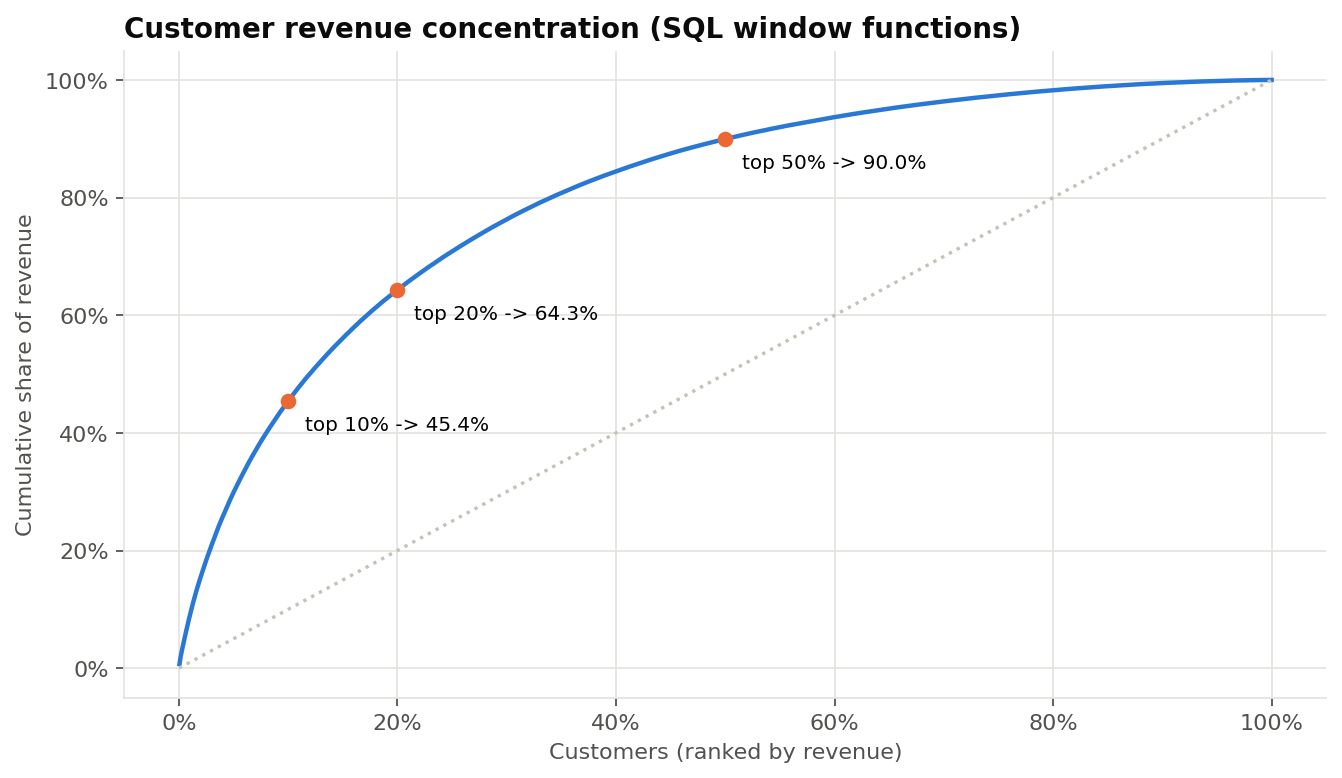

In [15]:
Image(str(FIG / "sql_customer_concentration.png"))

- **How it's built:** `ROW_NUMBER` ranks customers, a running `SUM() OVER` gives cumulative revenue, and `SUM() OVER ()` gives the percentage of the total.
- **Result:** the top 20% of customers hold 64% of revenue.
- **Saved for Power BI:** the full ranked table is saved as `outputs/tables/customer_revenue_concentration.csv` for the Customer Intelligence page.

## 6. RFM & ML segmentation (analysing the Python outputs)

In [16]:
show("seg_rfm_summary", 11)

**seg_rfm_summary** - RFM segment summary - customers, revenue, profit, average revenue / frequency / recency, contribution %

```sql
WITH cust AS (                                   -- revenue and profit recomputed from the transactions
    SELECT customer_id, SUM(sales) AS revenue, SUM(profit) AS profit
    FROM vw_delivered_sales
    GROUP BY customer_id
)
SELECT r.rfm_segment                                                        AS segment,
       d.value_activity_group,
       COUNT(*)                                                             AS customer_count,
       ROUND(SUM(c.revenue), 2)                                             AS revenue,
       ROUND(SUM(c.profit), 2)                                              AS profit,
       ROUND(AVG(c.revenue), 2)                                             AS avg_revenue_per_customer,
       ROUND(AVG(r.frequency_orders), 2)                                    AS avg_frequency,
       ROUND(AVG(r.recency_days), 1)                                        AS avg_recency_days,
       ROUND(100.0 * SUM(c.revenue) / SUM(SUM(c.revenue)) OVER (), 2)       AS revenue_contribution_pct,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)                   AS customer_pct
FROM customer_rfm r
JOIN rfm_segment_definitions d ON d.segment_name = r.rfm_segment
JOIN cust c                    ON c.customer_id  = r.customer_id
GROUP BY r.rfm_segment, d.value_activity_group, d.priority
ORDER BY d.priority;
```

,segment,value_activity_group,customer_count,revenue,profit,avg_revenue_per_customer,avg_frequency,avg_recency_days,revenue_contribution_pct,customer_pct
0,Champions,Active high value,334,"32,330,090.40","7,119,609.82","96,796.68",15.43,32.60,53.83,16.83
1,Loyal Customers,Active high value,240,"8,578,897.60","2,016,201.85","35,745.41",7.18,91.20,14.28,12.10
2,Potential Loyalists,Developing,152,"2,191,483.35","555,607.71","14,417.65",4.20,46.60,3.65,7.66
3,Recent Customers,Developing,91,"488,562.60","169,577.85","5,368.82",2.23,17.80,0.81,4.59
4,Promising,Developing,110,"562,907.70","193,656.10","5,117.34",2.20,59.40,0.94,5.54
5,Needs Attention,Slipping,123,"1,553,870.95","455,542.73","12,633.10",4.47,120.70,2.59,6.20
6,About to Sleep,Slipping,143,"605,262.25","185,225.47","4,232.60",2.12,115.40,1.01,7.21
7,Can't Lose Them,Slipping,79,"4,285,311.30","872,657.28","54,244.45",9.80,228.30,7.14,3.98
8,At Risk,Slipping,263,"6,763,493.30","1,619,385.49","25,716.70",5.90,259.30,11.26,13.26
9,Hibernating,Inactive,148,"975,827.80","335,890.75","6,593.43",3.07,199.00,1.62,7.46


,segment,value_activity_group,customer_count,revenue,profit,avg_revenue_per_customer,avg_frequency,avg_recency_days,revenue_contribution_pct,customer_pct
0,Champions,Active high value,334,"32,330,090.40","7,119,609.82","96,796.68",15.43,32.60,53.83,16.83
1,Loyal Customers,Active high value,240,"8,578,897.60","2,016,201.85","35,745.41",7.18,91.20,14.28,12.10
2,Potential Loyalists,Developing,152,"2,191,483.35","555,607.71","14,417.65",4.20,46.60,3.65,7.66
3,Recent Customers,Developing,91,"488,562.60","169,577.85","5,368.82",2.23,17.80,0.81,4.59
4,Promising,Developing,110,"562,907.70","193,656.10","5,117.34",2.20,59.40,0.94,5.54
5,Needs Attention,Slipping,123,"1,553,870.95","455,542.73","12,633.10",4.47,120.70,2.59,6.20
6,About to Sleep,Slipping,143,"605,262.25","185,225.47","4,232.60",2.12,115.40,1.01,7.21
7,Can't Lose Them,Slipping,79,"4,285,311.30","872,657.28","54,244.45",9.80,228.30,7.14,3.98
8,At Risk,Slipping,263,"6,763,493.30","1,619,385.49","25,716.70",5.90,259.30,11.26,13.26
9,Hibernating,Inactive,148,"975,827.80","335,890.75","6,593.43",3.07,199.00,1.62,7.46


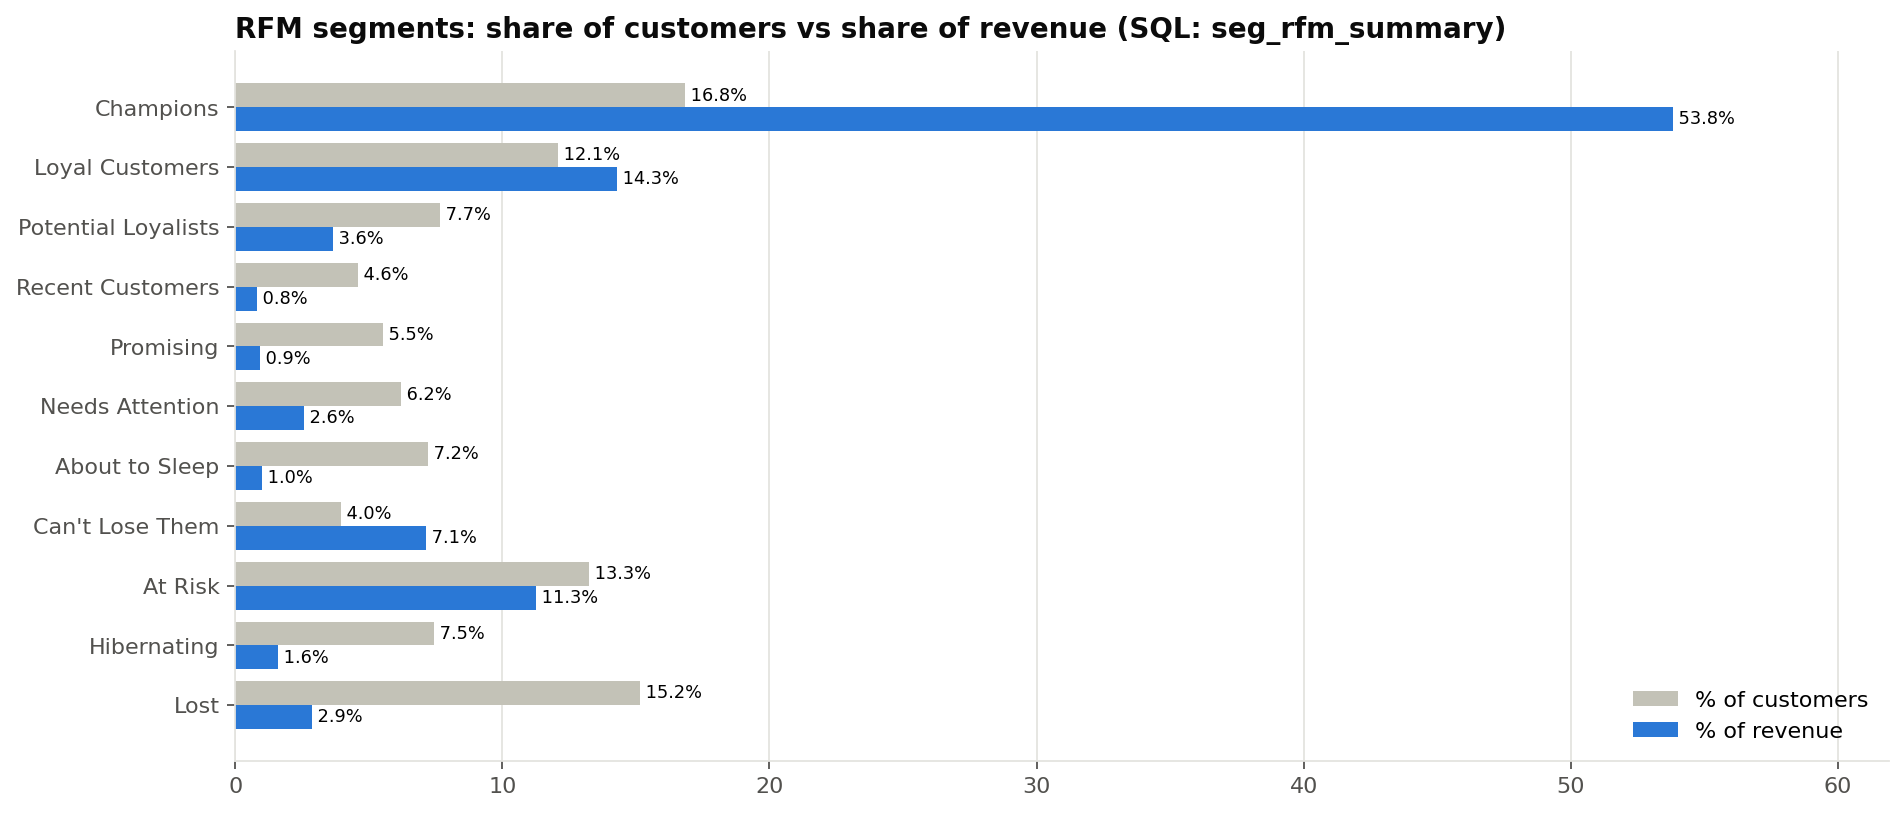

In [17]:
Image(str(FIG / "sql_revenue_by_rfm_segment.png"))

In [18]:
show("seg_ml_cluster_summary", 15)

**seg_ml_cluster_summary** - ML cluster size, revenue, profit and contribution (Step 6 K-Means)

```sql
SELECT m.cluster_id, m.cluster_label,
       COUNT(DISTINCT s.customer_id)                                        AS customer_count,
       ROUND(100.0 * COUNT(DISTINCT s.customer_id)
             / (SELECT COUNT(*) FROM customer_segments), 2)                  AS customer_pct,
       ROUND(SUM(d.sales), 2)                                               AS revenue,
       ROUND(SUM(d.profit), 2)                                              AS profit,
       ROUND(100.0 * SUM(d.profit) / SUM(d.sales), 2)                       AS profit_margin_pct,
       ROUND(100.0 * SUM(d.sales) / (SELECT SUM(sales) FROM vw_delivered_sales), 2) AS revenue_contribution_pct,
       ROUND(SUM(d.sales) / COUNT(DISTINCT s.customer_id), 2)               AS revenue_per_customer
FROM ml_clusters m
JOIN customer_segments s  ON s.cluster_id  = m.cluster_id
JOIN vw_delivered_sales d ON d.customer_id = s.customer_id
GROUP BY m.cluster_id, m.cluster_label
ORDER BY m.cluster_id;
```

,cluster_id,cluster_label,customer_count,customer_pct,revenue,profit,profit_margin_pct,revenue_contribution_pct,revenue_per_customer
0,0,"High-Value, Active",364,18.35,"33,433,867.35","7,410,971.15",22.17,55.67,"91,851.28"
1,1,"Low-Value, Active",453,22.83,"3,016,273.30","954,476.26",31.64,5.02,"6,658.44"
2,2,"Mid-Value, Lapsing",753,37.95,"21,256,257.95","4,987,670.74",23.46,35.39,"28,228.76"
3,3,"Low-Value, Inactive",414,20.87,"2,350,170.55","669,433.43",28.48,3.91,"5,676.74"


,cluster_id,cluster_label,customer_count,customer_pct,revenue,profit,profit_margin_pct,revenue_contribution_pct,revenue_per_customer
0,0,"High-Value, Active",364,18.35,"33,433,867.35","7,410,971.15",22.17,55.67,"91,851.28"
1,1,"Low-Value, Active",453,22.83,"3,016,273.30","954,476.26",31.64,5.02,"6,658.44"
2,2,"Mid-Value, Lapsing",753,37.95,"21,256,257.95","4,987,670.74",23.46,35.39,"28,228.76"
3,3,"Low-Value, Inactive",414,20.87,"2,350,170.55","669,433.43",28.48,3.91,"5,676.74"


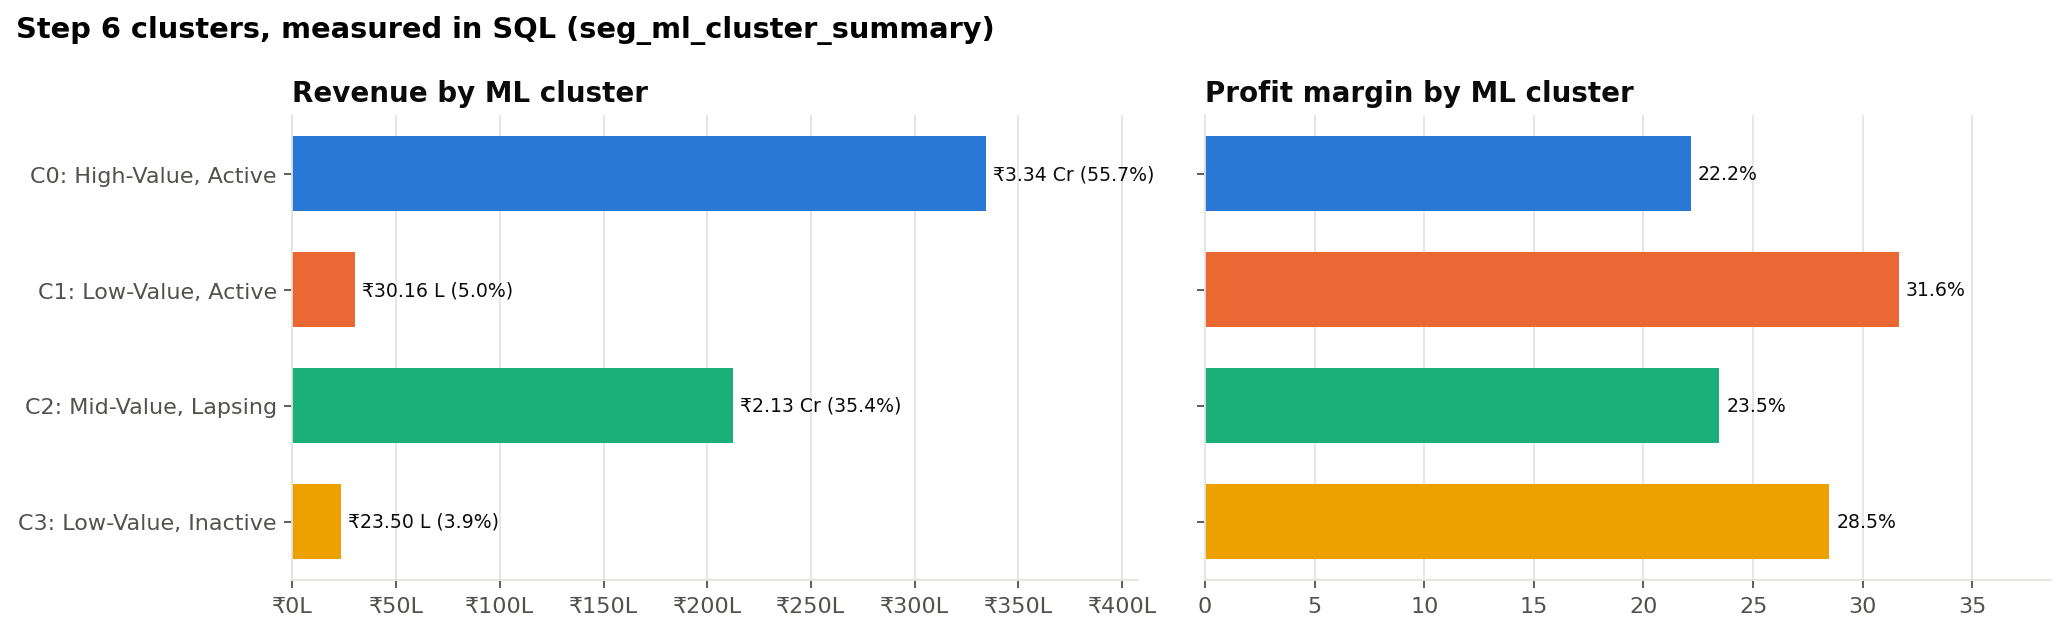

In [19]:
Image(str(FIG / "sql_revenue_by_ml_cluster.png"))

In [20]:
show("seg_rfm_vs_cluster", 11)

**seg_rfm_vs_cluster** - RFM segment x ML cluster - customer counts (how the two segmentations overlap)

```sql
SELECT r.rfm_segment,
       SUM(CASE WHEN s.cluster_id = 0 THEN 1 ELSE 0 END) AS cluster_0,
       SUM(CASE WHEN s.cluster_id = 1 THEN 1 ELSE 0 END) AS cluster_1,
       SUM(CASE WHEN s.cluster_id = 2 THEN 1 ELSE 0 END) AS cluster_2,
       SUM(CASE WHEN s.cluster_id = 3 THEN 1 ELSE 0 END) AS cluster_3,
       COUNT(*)                                          AS total
FROM customer_rfm r
JOIN customer_segments s       ON s.customer_id = r.customer_id
JOIN rfm_segment_definitions d ON d.segment_name = r.rfm_segment
GROUP BY r.rfm_segment, d.priority
ORDER BY d.priority;
```

,rfm_segment,cluster_0,cluster_1,cluster_2,cluster_3,total
0,Champions,324,0,10,0,334
1,Loyal Customers,39,0,201,0,240
2,Potential Loyalists,0,102,50,0,152
3,Recent Customers,0,91,0,0,91
4,Promising,0,110,0,0,110
5,Needs Attention,0,28,95,0,123
6,About to Sleep,0,118,0,25,143
7,Can't Lose Them,1,0,78,0,79
8,At Risk,0,0,256,7,263
9,Hibernating,0,4,52,92,148


,rfm_segment,cluster_0,cluster_1,cluster_2,cluster_3,total
0,Champions,324,0,10,0,334
1,Loyal Customers,39,0,201,0,240
2,Potential Loyalists,0,102,50,0,152
3,Recent Customers,0,91,0,0,91
4,Promising,0,110,0,0,110
5,Needs Attention,0,28,95,0,123
6,About to Sleep,0,118,0,25,143
7,Can't Lose Them,1,0,78,0,79
8,At Risk,0,0,256,7,263
9,Hibernating,0,4,52,92,148


- **No re-segmenting in SQL:** it reads the Step 5 and Step 6 assignments and measures them against the transactions.
- **Champions:** 17% of customers and 54% of revenue.
- **K-Means High-Value, Active cluster:** 18% of customers and 56% of revenue.
- **Saved segment table:** `outputs/tables/customer_segment_sql_analysis.csv`.

## 7. Product analytics

In [21]:
show("prod_category_performance", 15)

**prod_category_performance** - Category revenue, profit, margin and share

```sql
SELECT category,
       COUNT(DISTINCT product_id)                                      AS products,
       SUM(quantity)                                                   AS units,
       ROUND(SUM(sales), 2)                                            AS revenue,
       ROUND(SUM(profit), 2)                                           AS profit,
       ROUND(100.0 * SUM(profit) / SUM(sales), 2)                      AS profit_margin_pct,
       ROUND(100.0 * SUM(sales) / SUM(SUM(sales)) OVER (), 2)          AS revenue_share_pct,
       ROUND(100.0 * SUM(profit) / SUM(SUM(profit)) OVER (), 2)        AS profit_share_pct,
       RANK() OVER (ORDER BY SUM(profit) / SUM(sales) DESC)            AS margin_rank
FROM vw_delivered_sales
GROUP BY category
ORDER BY revenue DESC;
```

,category,products,units,revenue,profit,profit_margin_pct,revenue_share_pct,profit_share_pct,margin_rank
0,Electronics,13,3488,"30,090,652.55","3,265,843.69",10.85,50.10,23.29,6
1,Fashion,11,7154,"12,057,741.00","5,157,592.42",42.77,20.08,36.78,2
2,Home & Kitchen,11,4294,"10,377,382.80","2,926,231.02",28.20,17.28,20.87,4
3,Beauty,9,4653,"3,401,963.45","1,581,571.20",46.49,5.66,11.28,1
4,Sports,9,1168,"2,991,748.40","764,740.99",25.56,4.98,5.45,5
5,Books,8,2015,"1,137,080.95","326,572.26",28.72,1.89,2.33,3


,category,products,units,revenue,profit,profit_margin_pct,revenue_share_pct,profit_share_pct,margin_rank
0,Electronics,13,3488,"30,090,652.55","3,265,843.69",10.85,50.10,23.29,6
1,Fashion,11,7154,"12,057,741.00","5,157,592.42",42.77,20.08,36.78,2
2,Home & Kitchen,11,4294,"10,377,382.80","2,926,231.02",28.20,17.28,20.87,4
3,Beauty,9,4653,"3,401,963.45","1,581,571.20",46.49,5.66,11.28,1
4,Sports,9,1168,"2,991,748.40","764,740.99",25.56,4.98,5.45,5
5,Books,8,2015,"1,137,080.95","326,572.26",28.72,1.89,2.33,3


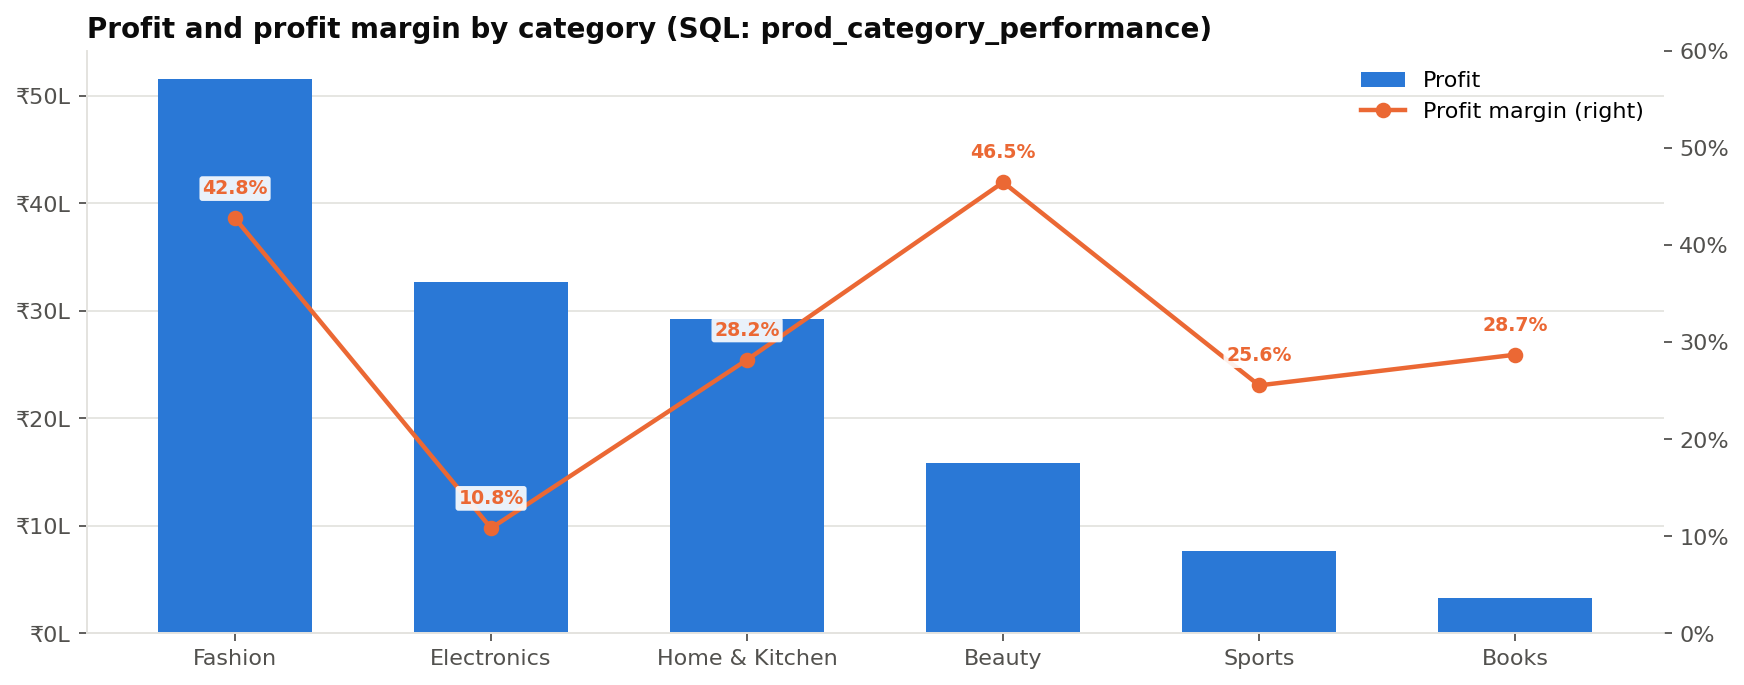

In [22]:
Image(str(FIG / "sql_category_profit_margin.png"))

In [23]:
show("prod_profitability", 10)

**prod_profitability** - Product profitability - quantity, revenue, cost, profit, margin, average discount, average price

```sql
WITH all_lines AS (
    SELECT product_id,
           COUNT(*)                                                   AS all_lines,
           SUM(CASE WHEN order_status <> 'Delivered' THEN 1 ELSE 0 END) AS returned_or_cancelled_lines
    FROM order_items
    GROUP BY product_id
)
SELECT d.product_id, d.product_name, d.category, d.sub_category,
       SUM(d.quantity)                                                 AS quantity,
       ROUND(SUM(d.sales), 2)                                          AS revenue,
       ROUND(SUM(d.cost), 2)                                           AS cost,
       ROUND(SUM(d.profit), 2)                                         AS profit,
       ROUND(100.0 * SUM(d.profit) / SUM(d.sales), 2)                  AS profit_margin_pct,
       ROUND(100.0 * AVG(d.discount), 2)                               AS avg_discount_pct,
       ROUND(SUM(d.sales) / SUM(d.quantity), 2)                        AS avg_selling_price,
       ROUND(AVG(d.unit_price), 2)                                     AS avg_list_price,
       ROUND(100.0 * a.returned_or_cancelled_lines / a.all_lines, 2)   AS return_cancel_rate_pct,
       RANK() OVER (ORDER BY SUM(d.profit) DESC)                       AS profit_rank
FROM vw_delivered_sales d
LEFT JOIN all_lines a ON a.product_id = d.product_id
GROUP BY d.product_id, d.product_name, d.category, d.sub_category
ORDER BY profit DESC;
```

,product_id,product_name,category,sub_category,quantity,revenue,cost,profit,profit_margin_pct,avg_discount_pct,avg_selling_price,avg_list_price,return_cancel_rate_pct,profit_rank
0,FAS-006,Running Shoes,Fashion,Footwear,698,"1,901,564.15","1,185,519.35","716,044.80",37.66,16.58,"2,724.30","3,269.93",13.76,1
1,HOM-002,Air Fryer 4L,Home & Kitchen,Kitchen Appliances,443,"2,563,348.30","1,966,974.02","596,374.28",23.27,11.40,"5,786.34","6,533.61",7.30,2
2,FAS-003,Women's Printed Kurta,Fashion,Women's Clothing,1081,"1,171,038.20","593,050.57","577,987.63",49.36,16.49,"1,083.29","1,307.63",14.65,3
3,FAS-001,Men's Cotton Casual Shirt,Fashion,Men's Clothing,1013,"1,211,754.10","646,076.80","565,677.30",46.68,15.33,"1,196.20","1,418.33",15.03,4
4,FAS-007,Casual Sneakers,Fashion,Footwear,674,"1,358,042.40","808,698.51","549,343.89",40.45,15.77,"2,014.90","2,398.90",11.86,5
5,FAS-004,Women's Cotton Saree,Fashion,Women's Clothing,605,"1,371,889.80","827,589.32","544,300.48",39.68,16.95,"2,267.59","2,731.33",14.58,6
6,FAS-002,Men's Slim Fit Jeans,Fashion,Men's Clothing,760,"1,245,899.95","716,817.74","529,082.21",42.47,16.26,"1,639.34","1,964.18",14.76,7
7,ELE-008,Noise-Cancelling Headphones,Electronics,Audio,274,"2,181,427.75","1,673,781.72","507,646.03",23.27,8.65,"7,961.42","8,719.68",7.01,8
8,HOM-001,Mixer Grinder 750W,Home & Kitchen,Kitchen Appliances,477,"1,614,276.30","1,199,624.72","414,651.58",25.69,10.90,"3,384.23","3,809.02",7.42,9
9,FAS-010,Analog Wrist Watch,Fashion,Fashion Accessories,389,"898,503.20","497,023.60","401,479.60",44.68,14.35,"2,309.78","2,723.47",12.90,10


,product_id,product_name,category,sub_category,quantity,revenue,cost,profit,profit_margin_pct,avg_discount_pct,avg_selling_price,avg_list_price,return_cancel_rate_pct,profit_rank
0,FAS-006,Running Shoes,Fashion,Footwear,698,"1,901,564.15","1,185,519.35","716,044.80",37.66,16.58,"2,724.30","3,269.93",13.76,1
1,HOM-002,Air Fryer 4L,Home & Kitchen,Kitchen Appliances,443,"2,563,348.30","1,966,974.02","596,374.28",23.27,11.40,"5,786.34","6,533.61",7.30,2
2,FAS-003,Women's Printed Kurta,Fashion,Women's Clothing,1081,"1,171,038.20","593,050.57","577,987.63",49.36,16.49,"1,083.29","1,307.63",14.65,3
3,FAS-001,Men's Cotton Casual Shirt,Fashion,Men's Clothing,1013,"1,211,754.10","646,076.80","565,677.30",46.68,15.33,"1,196.20","1,418.33",15.03,4
4,FAS-007,Casual Sneakers,Fashion,Footwear,674,"1,358,042.40","808,698.51","549,343.89",40.45,15.77,"2,014.90","2,398.90",11.86,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56,BOO-001,Contemporary Fiction Paperback,Books,Fiction,356,"143,904.90","102,444.39","41,460.51",28.81,7.08,404.23,435.68,9.91,57
57,BOO-004,Self-Help Bestseller,Books,Non-Fiction,358,"123,348.60","83,705.83","39,642.77",32.14,8.80,344.55,377.90,5.45,58
58,BOO-008,Kids Activity Book Set,Books,Children,160,"78,909.90","55,040.65","23,869.25",30.25,9.89,493.19,545.63,3.30,59
59,BOO-007,Children's Illustrated Storybook,Books,Children,250,"74,777.20","53,070.37","21,706.83",29.03,8.84,299.11,326.37,6.58,60


In [24]:
show("prod_discount_bands", 15)

**prod_discount_bands** - Discount level vs revenue, profit and margin

```sql
SELECT CASE WHEN discount = 0 THEN '0%'
            WHEN discount <= 0.10 THEN '1-10%'
            WHEN discount <= 0.20 THEN '11-20%'
            WHEN discount <= 0.30 THEN '21-30%'
            ELSE '31-40%' END                                          AS discount_band,
       MIN(discount)                                                   AS band_min,
       COUNT(*)                                                        AS order_lines,
       ROUND(SUM(sales), 2)                                            AS revenue,
       ROUND(SUM(profit), 2)                                           AS profit,
       ROUND(100.0 * SUM(profit) / SUM(sales), 2)                      AS profit_margin_pct,
       ROUND(AVG(sales), 2)                                            AS avg_revenue_per_line,
       ROUND(100.0 * SUM(CASE WHEN profit < 0 THEN 1 ELSE 0 END) / COUNT(*), 2) AS loss_making_lines_pct
FROM vw_delivered_sales
GROUP BY discount_band
ORDER BY band_min;
```

,discount_band,band_min,order_lines,revenue,profit,profit_margin_pct,avg_revenue_per_line,loss_making_lines_pct
0,0%,0.00,4548,"19,351,670.00","5,671,055.27",29.31,"4,254.98",0.00
1,1-10%,0.05,4145,"18,842,475.20","3,652,045.08",19.38,"4,545.83",0.55
2,11-20%,0.15,5429,"15,824,580.20","3,411,465.29",21.56,"2,914.82",2.93
3,21-30%,0.25,2346,"5,355,815.60","1,148,631.30",21.45,"2,282.96",2.26
4,31-40%,0.35,392,"682,028.15","139,354.64",20.43,"1,739.87",3.57


,discount_band,band_min,order_lines,revenue,profit,profit_margin_pct,avg_revenue_per_line,loss_making_lines_pct
0,0%,0.00,4548,"19,351,670.00","5,671,055.27",29.31,"4,254.98",0.00
1,1-10%,0.05,4145,"18,842,475.20","3,652,045.08",19.38,"4,545.83",0.55
2,11-20%,0.15,5429,"15,824,580.20","3,411,465.29",21.56,"2,914.82",2.93
3,21-30%,0.25,2346,"5,355,815.60","1,148,631.30",21.45,"2,282.96",2.26
4,31-40%,0.35,392,"682,028.15","139,354.64",20.43,"1,739.87",3.57


In [25]:
show("prod_investigate", 15)

**prod_investigate** - Products that may need investigation (margin far below their category, or high return/cancel rate)

```sql
WITH p AS (
    SELECT d.product_id, d.product_name, d.category,
           SUM(d.sales) AS revenue, SUM(d.profit) AS profit
    FROM vw_delivered_sales d
    GROUP BY d.product_id, d.product_name, d.category
),
cat AS (
    SELECT category, SUM(profit) / SUM(sales) AS cat_margin FROM vw_delivered_sales GROUP BY category
),
rr AS (
    SELECT product_id, 1.0 * SUM(CASE WHEN order_status <> 'Delivered' THEN 1 ELSE 0 END) / COUNT(*) AS rc_rate
    FROM order_items GROUP BY product_id
),
overall AS (SELECT 1.0 * SUM(CASE WHEN order_status <> 'Delivered' THEN 1 ELSE 0 END) / COUNT(*) AS rc FROM order_items)
SELECT p.product_id, p.product_name, p.category,
       ROUND(p.revenue, 2)                                  AS revenue,
       ROUND(100.0 * p.profit / p.revenue, 2)               AS profit_margin_pct,
       ROUND(100.0 * c.cat_margin, 2)                       AS category_margin_pct,
       ROUND(100.0 * rr.rc_rate, 2)                         AS return_cancel_rate_pct,
       ROUND(100.0 * (SELECT rc FROM overall), 2)           AS overall_return_cancel_rate_pct,
       CASE WHEN p.profit / p.revenue < 0.5 * c.cat_margin AND rr.rc_rate > 1.5 * (SELECT rc FROM overall)
                THEN 'low margin AND high return/cancel rate'
            WHEN p.profit / p.revenue < 0.5 * c.cat_margin THEN 'margin < half of category margin'
            ELSE 'return/cancel rate > 1.5x overall' END   AS reason
FROM p
JOIN cat c ON c.category  = p.category
JOIN rr    ON rr.product_id = p.product_id
WHERE p.profit / p.revenue < 0.5 * c.cat_margin
   OR rr.rc_rate > 1.5 * (SELECT rc FROM overall)
ORDER BY p.revenue DESC;


-- 5. REGIONAL ANALYTICS
```

,product_id,product_name,category,revenue,profit_margin_pct,category_margin_pct,return_cancel_rate_pct,overall_return_cancel_rate_pct,reason
0,ELE-002,Nova X7 Pro Smartphone 256GB,Electronics,"5,737,729.15",4.69,10.85,6.29,9.69,margin < half of category margin
1,ELE-005,AeroBook Pro 16 Laptop,Electronics,"2,906,412.50",2.16,10.85,8.57,9.69,margin < half of category margin
2,ELE-006,43-inch 4K Smart TV,Electronics,"2,498,330.65",-1.67,10.85,6.74,9.69,margin < half of category margin
3,FAS-004,Women's Cotton Saree,Fashion,"1,371,889.80",39.68,42.77,14.58,9.69,return/cancel rate > 1.5x overall
4,FAS-002,Men's Slim Fit Jeans,Fashion,"1,245,899.95",42.47,42.77,14.76,9.69,return/cancel rate > 1.5x overall
5,FAS-001,Men's Cotton Casual Shirt,Fashion,"1,211,754.10",46.68,42.77,15.03,9.69,return/cancel rate > 1.5x overall
6,FAS-003,Women's Printed Kurta,Fashion,"1,171,038.20",49.36,42.77,14.65,9.69,return/cancel rate > 1.5x overall
7,FAS-008,Leather Formal Shoes,Fashion,"1,034,515.00",34.27,42.77,15.92,9.69,return/cancel rate > 1.5x overall
8,SPO-004,Hybrid Bicycle 21-Speed,Sports,"1,007,011.20",11.90,25.56,6.35,9.69,margin < half of category margin
9,FAS-005,Women's Western Dress,Fashion,"890,284.75",44.93,42.77,16.71,9.69,return/cancel rate > 1.5x overall


,product_id,product_name,category,revenue,profit_margin_pct,category_margin_pct,return_cancel_rate_pct,overall_return_cancel_rate_pct,reason
0,ELE-002,Nova X7 Pro Smartphone 256GB,Electronics,"5,737,729.15",4.69,10.85,6.29,9.69,margin < half of category margin
1,ELE-005,AeroBook Pro 16 Laptop,Electronics,"2,906,412.50",2.16,10.85,8.57,9.69,margin < half of category margin
2,ELE-006,43-inch 4K Smart TV,Electronics,"2,498,330.65",-1.67,10.85,6.74,9.69,margin < half of category margin
3,FAS-004,Women's Cotton Saree,Fashion,"1,371,889.80",39.68,42.77,14.58,9.69,return/cancel rate > 1.5x overall
4,FAS-002,Men's Slim Fit Jeans,Fashion,"1,245,899.95",42.47,42.77,14.76,9.69,return/cancel rate > 1.5x overall
5,FAS-001,Men's Cotton Casual Shirt,Fashion,"1,211,754.10",46.68,42.77,15.03,9.69,return/cancel rate > 1.5x overall
6,FAS-003,Women's Printed Kurta,Fashion,"1,171,038.20",49.36,42.77,14.65,9.69,return/cancel rate > 1.5x overall
7,FAS-008,Leather Formal Shoes,Fashion,"1,034,515.00",34.27,42.77,15.92,9.69,return/cancel rate > 1.5x overall
8,SPO-004,Hybrid Bicycle 21-Speed,Sports,"1,007,011.20",11.90,25.56,6.35,9.69,margin < half of category margin
9,FAS-005,Women's Western Dress,Fashion,"890,284.75",44.93,42.77,16.71,9.69,return/cancel rate > 1.5x overall


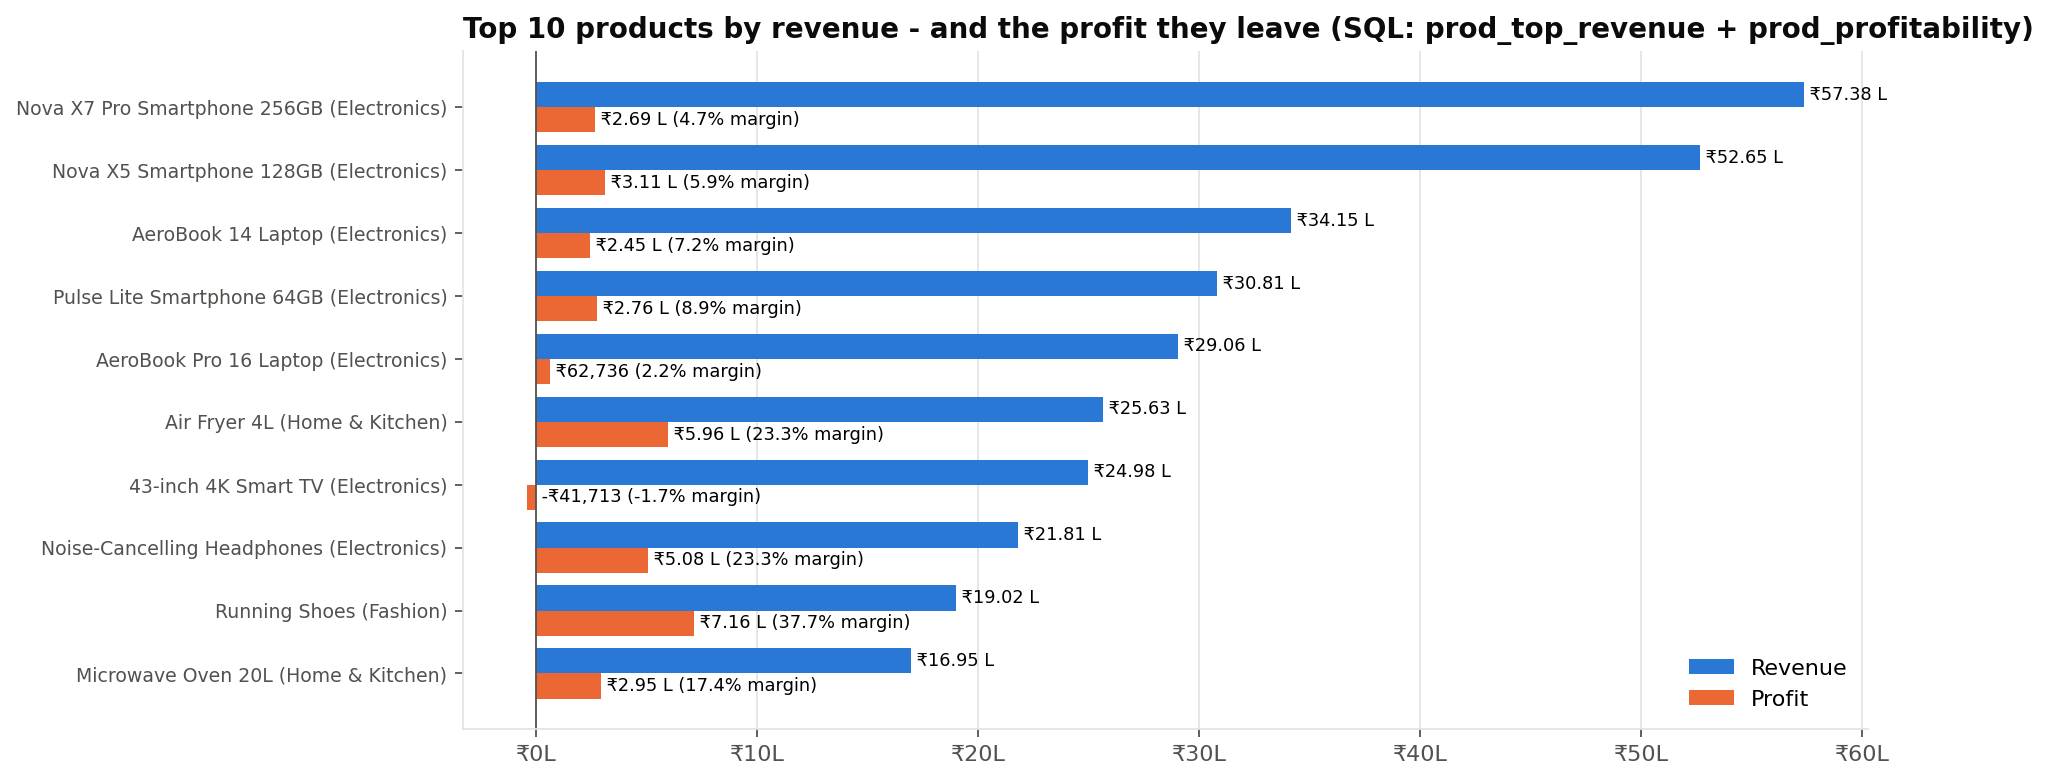

In [26]:
Image(str(FIG / "sql_top10_products.png"))

- **Category trade-off:** Electronics is half of revenue but has the lowest margin (10.8%), while Fashion and Beauty have margins above 40%.
- **Products to investigate:** the query flags 10 products, including three high-revenue Electronics items whose margin is less than half their category's.
- **Saved product table:** `outputs/tables/product_profitability.csv`.

## 8. Regional analytics

In [27]:
show("reg_performance", 15)

**reg_performance** - Revenue, profit, orders, customers and AOV by region

```sql
SELECT region,
       ROUND(SUM(sales), 2)                                            AS revenue,
       ROUND(SUM(profit), 2)                                           AS profit,
       ROUND(100.0 * SUM(profit) / SUM(sales), 2)                      AS profit_margin_pct,
       COUNT(DISTINCT order_id)                                        AS orders,
       COUNT(DISTINCT customer_id)                                     AS customers,
       ROUND(SUM(sales) / COUNT(DISTINCT order_id), 2)                 AS average_order_value,
       ROUND(SUM(sales) / COUNT(DISTINCT customer_id), 2)              AS revenue_per_customer,
       ROUND(100.0 * SUM(sales) / SUM(SUM(sales)) OVER (), 2)          AS revenue_share_pct
FROM vw_delivered_sales
GROUP BY region
ORDER BY revenue DESC;
```

,region,revenue,profit,profit_margin_pct,orders,customers,average_order_value,revenue_per_customer,revenue_share_pct
0,South,"16,225,938.40","3,700,176.94",22.80,3296,540,"4,922.92","30,048.03",27.02
1,North,"14,400,613.35","3,190,656.81",22.16,2819,444,"5,108.41","32,433.81",23.98
2,West,"14,357,145.80","3,360,503.40",23.41,2971,490,"4,832.43","29,300.30",23.91
3,Central,"7,633,672.45","1,928,071.03",25.26,1551,248,"4,921.77","30,780.94",12.71
4,East,"7,439,199.15","1,843,143.40",24.78,1575,262,"4,723.30","28,393.89",12.39


,region,revenue,profit,profit_margin_pct,orders,customers,average_order_value,revenue_per_customer,revenue_share_pct
0,South,"16,225,938.40","3,700,176.94",22.80,3296,540,"4,922.92","30,048.03",27.02
1,North,"14,400,613.35","3,190,656.81",22.16,2819,444,"5,108.41","32,433.81",23.98
2,West,"14,357,145.80","3,360,503.40",23.41,2971,490,"4,832.43","29,300.30",23.91
3,Central,"7,633,672.45","1,928,071.03",25.26,1551,248,"4,921.77","30,780.94",12.71
4,East,"7,439,199.15","1,843,143.40",24.78,1575,262,"4,723.30","28,393.89",12.39


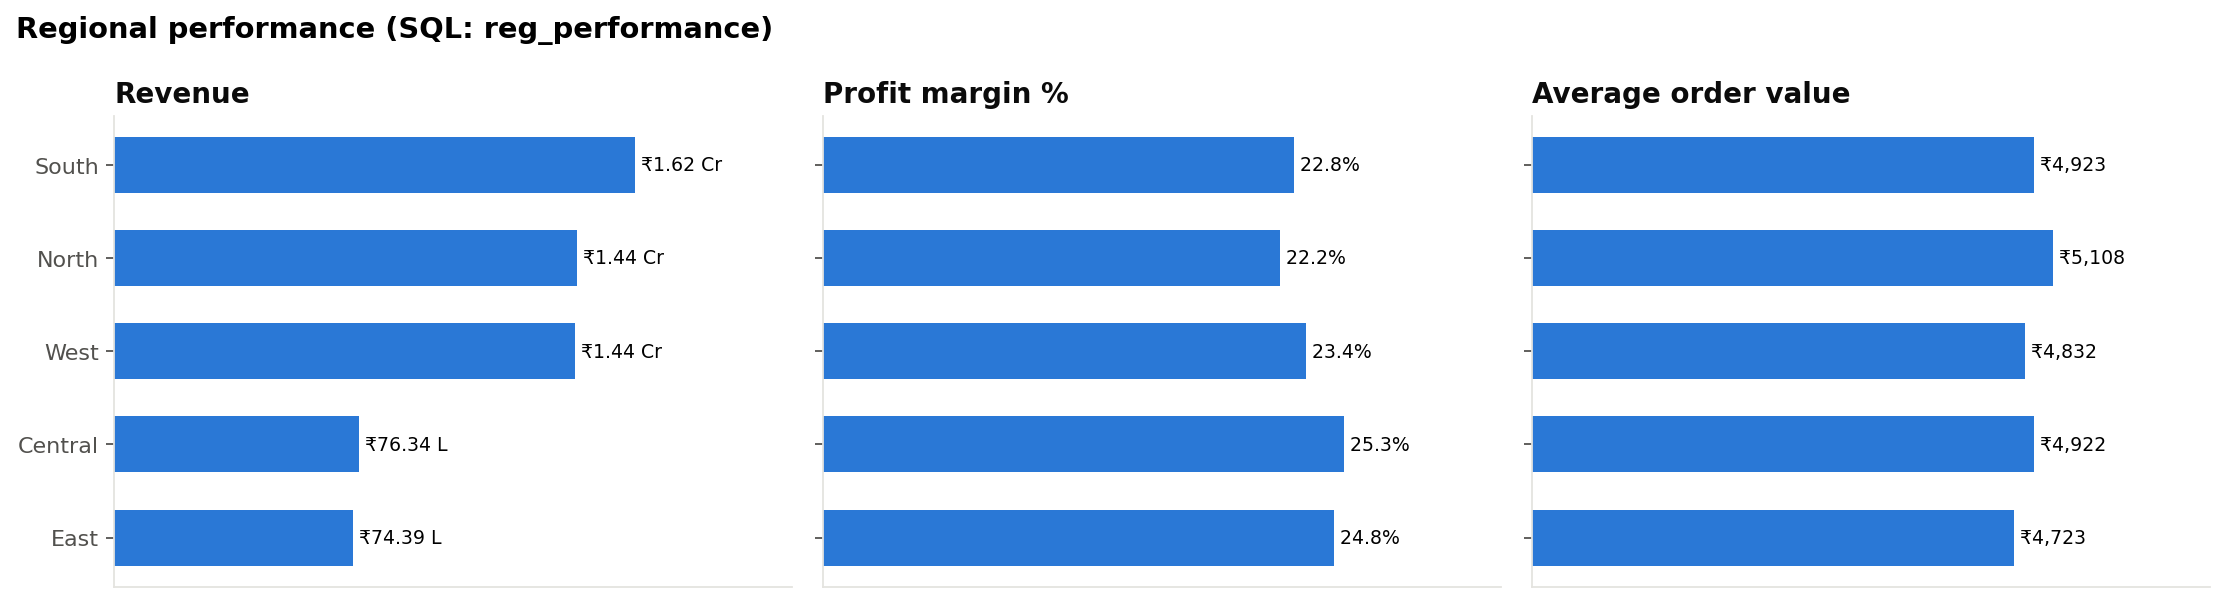

In [28]:
Image(str(FIG / "sql_region_performance.png"))

In [29]:
show("reg_category_matrix", 12)

**reg_category_matrix** - Category performance by region (revenue, margin, share of the region's revenue)

```sql
SELECT region, category,
       ROUND(SUM(sales), 2)                                                        AS revenue,
       ROUND(100.0 * SUM(profit) / SUM(sales), 2)                                  AS profit_margin_pct,
       ROUND(100.0 * SUM(sales) / SUM(SUM(sales)) OVER (PARTITION BY region), 2)   AS pct_of_region_revenue,
       RANK() OVER (PARTITION BY region ORDER BY SUM(sales) DESC)                  AS rank_in_region
FROM vw_delivered_sales
GROUP BY region, category
ORDER BY region, rank_in_region;
```

,region,category,revenue,profit_margin_pct,pct_of_region_revenue,rank_in_region
0,Central,Electronics,"3,514,393.30",12.16,46.04,1
1,Central,Fashion,"1,606,237.85",42.94,21.04,2
2,Central,Home & Kitchen,"1,472,601.15",30.55,19.29,3
3,Central,Beauty,"471,559.05",45.63,6.18,4
4,Central,Sports,"349,316.75",23.84,4.58,5
5,Central,Books,"219,564.35",28.50,2.88,6
6,East,Electronics,"3,564,106.65",11.98,47.91,1
7,East,Fashion,"1,625,251.90",43.35,21.85,2
8,East,Home & Kitchen,"1,251,292.45",28.12,16.82,3
9,East,Beauty,"455,935.40",47.32,6.13,4


,region,category,revenue,profit_margin_pct,pct_of_region_revenue,rank_in_region
0,Central,Electronics,"3,514,393.30",12.16,46.04,1
1,Central,Fashion,"1,606,237.85",42.94,21.04,2
2,Central,Home & Kitchen,"1,472,601.15",30.55,19.29,3
3,Central,Beauty,"471,559.05",45.63,6.18,4
4,Central,Sports,"349,316.75",23.84,4.58,5
5,Central,Books,"219,564.35",28.50,2.88,6
6,East,Electronics,"3,564,106.65",11.98,47.91,1
7,East,Fashion,"1,625,251.90",43.35,21.85,2
8,East,Home & Kitchen,"1,251,292.45",28.12,16.82,3
9,East,Beauty,"455,935.40",47.32,6.13,4


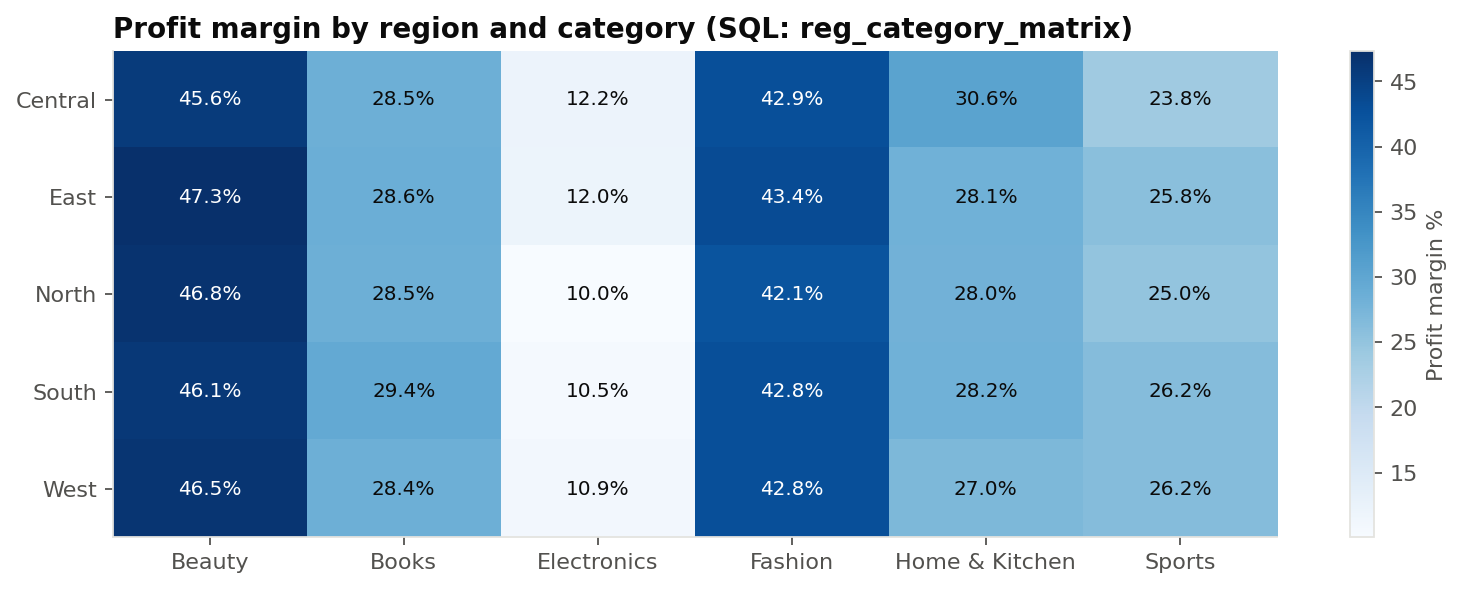

In [30]:
Image(str(FIG / "sql_region_category_margin.png"))

- **Revenue:** South is the largest region.
- **Margins:** they vary little between regions. Within each category, margins are similar in every region (BQ16: the largest gap is 1.7 points below the national figure), so regional margin differences mainly reflect each region's category mix.
- **BQ16:** no region-category pair falls more than 2 points below the national margin for that category.

## 9. Time-based analysis

In [31]:
show("time_monthly", 36)

**time_monthly** - Monthly revenue, profit, orders and customers with month-over-month and year-over-year growth

```sql
WITH m AS (
    SELECT order_month,
           SUM(sales) AS revenue, SUM(profit) AS profit,
           COUNT(DISTINCT order_id) AS orders, COUNT(DISTINCT customer_id) AS customers
    FROM vw_delivered_sales
    GROUP BY order_month
)
SELECT order_month,
       ROUND(revenue, 2)                                                   AS revenue,
       ROUND(profit, 2)                                                    AS profit,
       orders, customers,
       ROUND(revenue / orders, 2)                                          AS average_order_value,
       ROUND(100.0 * (revenue / LAG(revenue, 1)  OVER w - 1), 2)           AS mom_growth_pct,
       ROUND(100.0 * (revenue / LAG(revenue, 12) OVER w - 1), 2)           AS yoy_growth_pct,
       ROUND(AVG(revenue) OVER (ORDER BY order_month ROWS BETWEEN 2 PRECEDING AND CURRENT ROW), 2) AS rolling_3m_avg_revenue
FROM m
WINDOW w AS (ORDER BY order_month)
ORDER BY order_month;
```

,order_month,revenue,profit,orders,customers,average_order_value,mom_growth_pct,yoy_growth_pct,rolling_3m_avg_revenue
0,2023-01,"724,867.15","185,594.91",200,166,"3,624.34",NaN,NaN,"724,867.15"
1,2023-02,"572,756.75","185,157.63",147,139,"3,896.30",-20.98,NaN,"648,811.95"
2,2023-03,"921,616.85","195,919.88",150,137,"6,144.11",60.91,NaN,"739,746.92"
3,2023-04,"1,035,094.85","234,182.52",176,158,"5,881.22",12.31,NaN,"843,156.15"
4,2023-05,"889,389.70","232,084.85",192,173,"4,632.24",-14.08,NaN,"948,700.47"
5,2023-06,"696,767.45","185,120.39",166,147,"4,197.39",-21.66,NaN,"873,750.67"
6,2023-07,"1,045,739.00","260,600.15",247,216,"4,233.76",50.08,NaN,"877,298.72"
7,2023-08,"1,356,304.80","261,060.78",252,215,"5,382.16",29.70,NaN,"1,032,937.08"
8,2023-09,"975,785.45","270,211.30",229,202,"4,261.07",-28.06,NaN,"1,125,943.08"
9,2023-10,"1,847,708.75","311,449.51",376,308,"4,914.12",89.36,NaN,"1,393,266.33"


,order_month,revenue,profit,orders,customers,average_order_value,mom_growth_pct,yoy_growth_pct,rolling_3m_avg_revenue
0,2023-01,"724,867.15","185,594.91",200,166,"3,624.34",NaN,NaN,"724,867.15"
1,2023-02,"572,756.75","185,157.63",147,139,"3,896.30",-20.98,NaN,"648,811.95"
2,2023-03,"921,616.85","195,919.88",150,137,"6,144.11",60.91,NaN,"739,746.92"
3,2023-04,"1,035,094.85","234,182.52",176,158,"5,881.22",12.31,NaN,"843,156.15"
4,2023-05,"889,389.70","232,084.85",192,173,"4,632.24",-14.08,NaN,"948,700.47"
5,2023-06,"696,767.45","185,120.39",166,147,"4,197.39",-21.66,NaN,"873,750.67"
6,2023-07,"1,045,739.00","260,600.15",247,216,"4,233.76",50.08,NaN,"877,298.72"
7,2023-08,"1,356,304.80","261,060.78",252,215,"5,382.16",29.70,NaN,"1,032,937.08"
8,2023-09,"975,785.45","270,211.30",229,202,"4,261.07",-28.06,NaN,"1,125,943.08"
9,2023-10,"1,847,708.75","311,449.51",376,308,"4,914.12",89.36,NaN,"1,393,266.33"


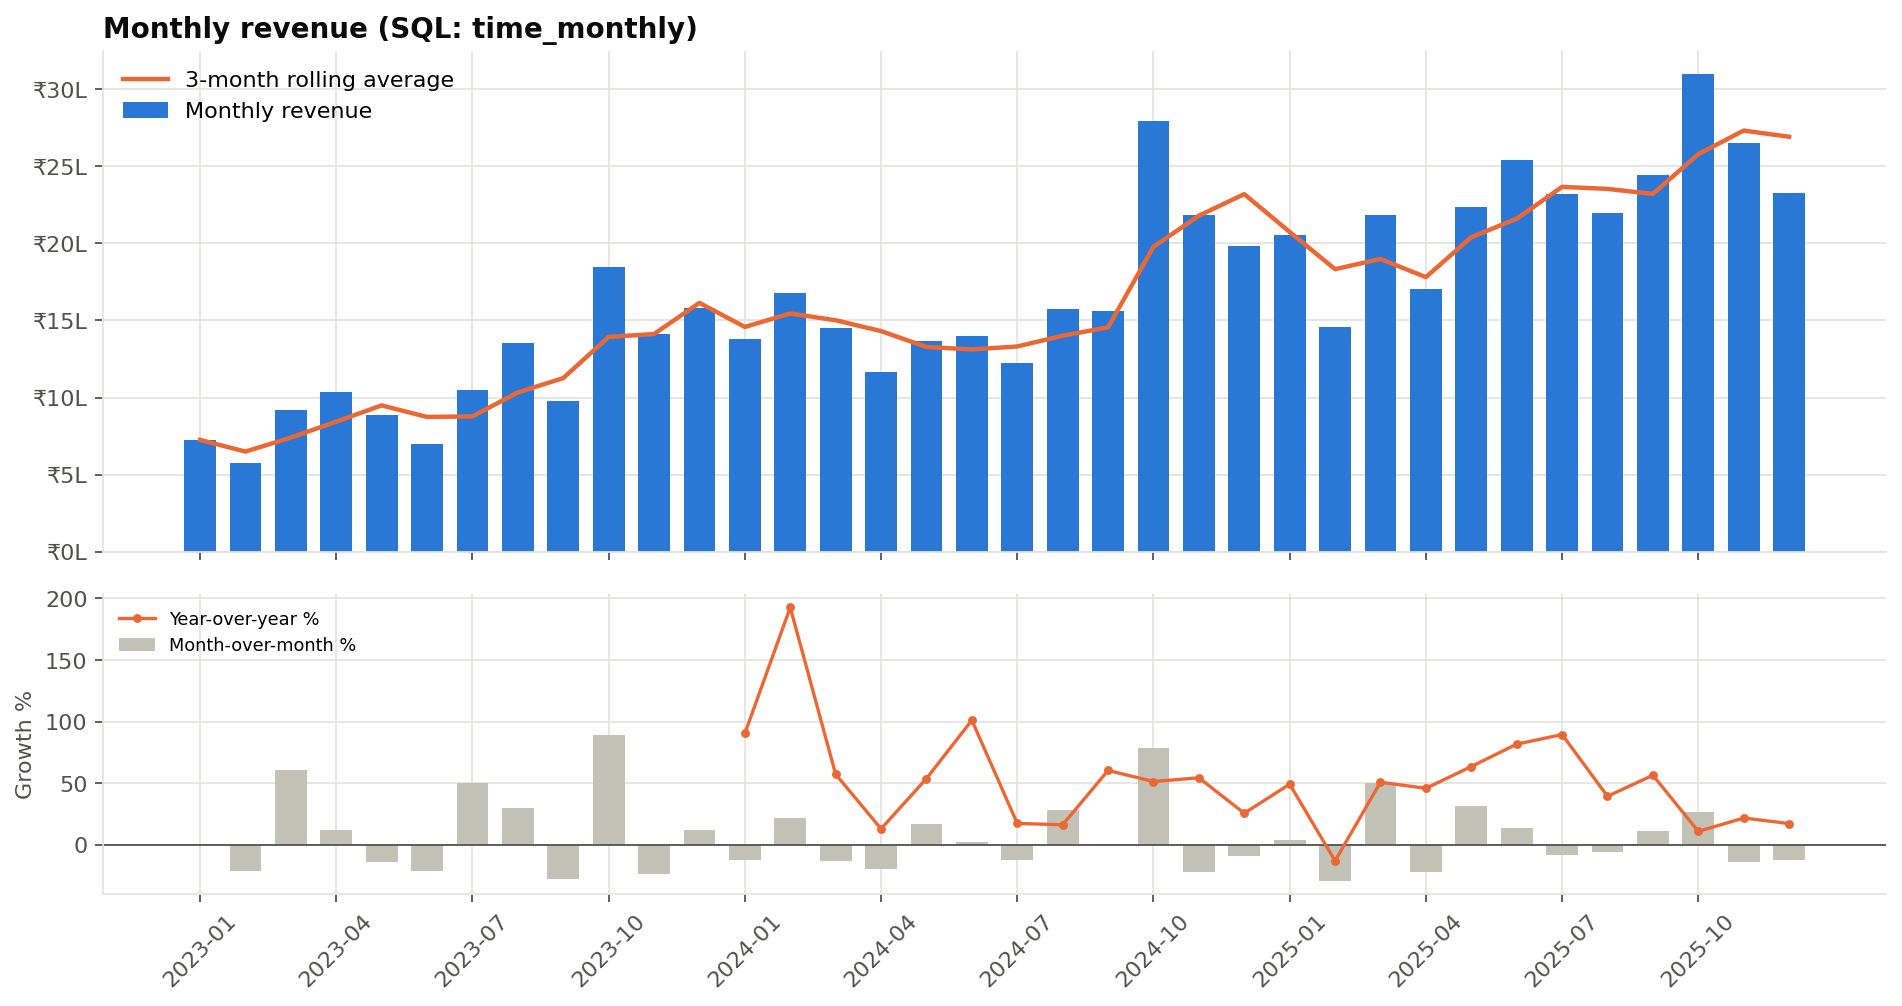

In [32]:
Image(str(FIG / "sql_monthly_revenue_growth.png"))

In [33]:
show("time_best_worst_months", 15)

**time_best_worst_months** - Highest- and lowest-revenue months

```sql
WITH m AS (
    SELECT order_month, SUM(sales) AS revenue FROM vw_delivered_sales GROUP BY order_month
),
r AS (
    SELECT order_month, revenue,
           RANK() OVER (ORDER BY revenue DESC) AS rank_high,
           RANK() OVER (ORDER BY revenue ASC)  AS rank_low
    FROM m
)
SELECT CASE WHEN rank_high <= 3 THEN 'Top ' || rank_high ELSE 'Bottom ' || rank_low END AS position,
       order_month, ROUND(revenue, 2) AS revenue
FROM r
WHERE rank_high <= 3 OR rank_low <= 3
ORDER BY revenue DESC;
```

,position,order_month,revenue
0,Top 1,2025-10,"3,097,837.75"
1,Top 2,2024-10,"2,795,219.00"
2,Top 3,2025-11,"2,654,877.85"
3,Bottom 3,2023-01,"724,867.15"
4,Bottom 2,2023-06,"696,767.45"
5,Bottom 1,2023-02,"572,756.75"


,position,order_month,revenue
0,Top 1,2025-10,"3,097,837.75"
1,Top 2,2024-10,"2,795,219.00"
2,Top 3,2025-11,"2,654,877.85"
3,Bottom 3,2023-01,"724,867.15"
4,Bottom 2,2023-06,"696,767.45"
5,Bottom 1,2023-02,"572,756.75"


- **How growth is calculated:** month-over-month and year-over-year growth use `LAG(…, 1)` and `LAG(…, 12)`.
- **Peaks and lows:** the three highest months are all October or November (2025-10, 2024-10, 2025-11); the three lowest are all in the first half of 2023.

## 10. Business intelligence questions (BQ01–BQ20)

In [34]:
bq = R["catalog"][R["catalog"]["File"] == "business_queries.sql"][["Query", "Title_or_Question", "Purpose", "Rows", "Techniques"]]
bq

,Query,Title_or_Question,Purpose,Rows,Techniques
37,BQ01,Which customers generate the highest revenue?,"Identify the accounts the business depends on most, for key-account management.",10,"LEFT JOIN, CTE (WITH), Window function, Ranking (RANK / ROW_NUMBER / NTILE), Percentage contribution (SUM() OVER ())..."
38,BQ02,Which customer segments contribute the most revenue?,Size each RFM segment's commercial weight to prioritise segment strategies.,11,"INNER JOIN, CTE (WITH), Window function, Ranking (RANK / ROW_NUMBER / NTILE), Percentage contribution (SUM() OVER ()..."
39,BQ03,Which products generate high revenue but relatively low profit?,"Find revenue drivers that contribute little profit (pricing, cost or discount review).",11,"CTE (WITH), Subquery, Window function, Ranking (RANK / ROW_NUMBER / NTILE), GROUP BY aggregation"
40,BQ04,Which categories have the highest profit margins?,Understand where each rupee of revenue earns the most profit (mix and promotion planning).,6,"Window function, Ranking (RANK / ROW_NUMBER / NTILE), Percentage contribution (SUM() OVER ()), GROUP BY aggregation"
41,BQ05,Which regions generate the highest revenue?,Allocate regional sales and marketing effort.,5,"Window function, Ranking (RANK / ROW_NUMBER / NTILE), Percentage contribution (SUM() OVER ()), GROUP BY aggregation"
42,BQ06,Which customers have high historical value but low recent activity?,"Build a re-engagement list of valuable customers who have gone quiet (potentially at-risk, not churned).",52,"INNER JOIN, CTE (WITH), Subquery, GROUP BY aggregation, Date functions"
43,BQ07,Which products have high sales volume but low profitability?,"Flag popular products whose unit economics may need attention (price, cost, discount).",2,"CTE (WITH), Window function, Ranking (RANK / ROW_NUMBER / NTILE), GROUP BY aggregation"
44,BQ08,How does discount level relate to profitability?,"Inform discount policy by showing margin and loss-making lines at each discount level, within category.",24,"CASE WHEN, Window function, Percentage contribution (SUM() OVER ()), GROUP BY aggregation"
45,BQ09,Which months generate the highest revenue?,"Plan inventory, staffing and campaigns around recurring peaks.",9,"CTE (WITH), Window function, Ranking (RANK / ROW_NUMBER / NTILE), Percentage contribution (SUM() OVER ()), GROUP BY ..."
46,BQ10,What percentage of total revenue comes from high-value customers?,Quantify revenue concentration for risk and retention planning.,2,"INNER JOIN, CASE WHEN, CTE (WITH), Subquery, Window function, Ranking (RANK / ROW_NUMBER / NTILE), GROUP BY aggregat..."


In [35]:
show("BQ02", 12)

**BQ02** - Which customer segments contribute the most revenue?

```sql
WITH c AS (SELECT customer_id, SUM(sales) AS revenue FROM vw_delivered_sales GROUP BY customer_id)
SELECT RANK() OVER (ORDER BY SUM(c.revenue) DESC)                   AS revenue_rank,
       r.rfm_segment,
       COUNT(*)                                                     AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)           AS customer_pct,
       ROUND(SUM(c.revenue), 2)                                     AS revenue,
       ROUND(100.0 * SUM(c.revenue) / SUM(SUM(c.revenue)) OVER (), 2) AS revenue_contribution_pct,
       ROUND(SUM(c.revenue) / COUNT(*), 2)                          AS revenue_per_customer
FROM customer_rfm r
JOIN c ON c.customer_id = r.customer_id
GROUP BY r.rfm_segment
ORDER BY revenue DESC;
```

,revenue_rank,rfm_segment,customers,customer_pct,revenue,revenue_contribution_pct,revenue_per_customer
0,1,Champions,334,16.83,"32,330,090.40",53.83,"96,796.68"
1,2,Loyal Customers,240,12.10,"8,578,897.60",14.28,"35,745.41"
2,3,At Risk,263,13.26,"6,763,493.30",11.26,"25,716.70"
3,4,Can't Lose Them,79,3.98,"4,285,311.30",7.14,"54,244.45"
4,5,Potential Loyalists,152,7.66,"2,191,483.35",3.65,"14,417.65"
5,6,Lost,301,15.17,"1,720,861.90",2.87,"5,717.15"
6,7,Needs Attention,123,6.20,"1,553,870.95",2.59,"12,633.10"
7,8,Hibernating,148,7.46,"975,827.80",1.62,"6,593.43"
8,9,About to Sleep,143,7.21,"605,262.25",1.01,"4,232.60"
9,10,Promising,110,5.54,"562,907.70",0.94,"5,117.34"


,revenue_rank,rfm_segment,customers,customer_pct,revenue,revenue_contribution_pct,revenue_per_customer
0,1,Champions,334,16.83,"32,330,090.40",53.83,"96,796.68"
1,2,Loyal Customers,240,12.10,"8,578,897.60",14.28,"35,745.41"
2,3,At Risk,263,13.26,"6,763,493.30",11.26,"25,716.70"
3,4,Can't Lose Them,79,3.98,"4,285,311.30",7.14,"54,244.45"
4,5,Potential Loyalists,152,7.66,"2,191,483.35",3.65,"14,417.65"
5,6,Lost,301,15.17,"1,720,861.90",2.87,"5,717.15"
6,7,Needs Attention,123,6.20,"1,553,870.95",2.59,"12,633.10"
7,8,Hibernating,148,7.46,"975,827.80",1.62,"6,593.43"
8,9,About to Sleep,143,7.21,"605,262.25",1.01,"4,232.60"
9,10,Promising,110,5.54,"562,907.70",0.94,"5,117.34"


In [36]:
show("BQ03", 12)

**BQ03** - Which products generate high revenue but relatively low profit?

```sql
WITH p AS (
    SELECT product_id, product_name, category, SUM(sales) AS revenue, SUM(profit) AS profit,
           SUM(profit) / SUM(sales) AS margin
    FROM vw_delivered_sales
    GROUP BY product_id, product_name, category
),
q AS (
    SELECT *, NTILE(4) OVER (ORDER BY revenue DESC) AS revenue_quartile,
              NTILE(4) OVER (ORDER BY margin ASC)   AS margin_quartile
    FROM p
)
SELECT product_id, product_name, category,
       ROUND(revenue, 2) AS revenue, ROUND(profit, 2) AS profit,
       ROUND(100.0 * margin, 2)                                               AS profit_margin_pct,
       ROUND(100.0 * (margin - (SELECT SUM(profit) / SUM(sales) FROM vw_delivered_sales v
                                WHERE v.category = q.category)), 2)          AS margin_gap_vs_category_pp
FROM q
WHERE revenue_quartile = 1 AND margin_quartile = 1
ORDER BY revenue DESC;
```

,product_id,product_name,category,revenue,profit,profit_margin_pct,margin_gap_vs_category_pp
0,ELE-002,Nova X7 Pro Smartphone 256GB,Electronics,"5,737,729.15","269,030.38",4.69,-6.16
1,ELE-001,Nova X5 Smartphone 128GB,Electronics,"5,264,715.85","311,212.61",5.91,-4.94
2,ELE-004,AeroBook 14 Laptop,Electronics,"3,414,957.25","245,177.46",7.18,-3.67
3,ELE-003,Pulse Lite Smartphone 64GB,Electronics,"3,080,617.25","275,845.33",8.95,-1.90
4,ELE-005,AeroBook Pro 16 Laptop,Electronics,"2,906,412.50","62,735.77",2.16,-8.69
5,HOM-002,Air Fryer 4L,Home & Kitchen,"2,563,348.30","596,374.28",23.27,-4.93
6,ELE-006,43-inch 4K Smart TV,Electronics,"2,498,330.65","-41,713.11",-1.67,-12.52
7,ELE-008,Noise-Cancelling Headphones,Electronics,"2,181,427.75","507,646.03",23.27,12.42
8,HOM-004,Microwave Oven 20L,Home & Kitchen,"1,694,728.40","295,395.80",17.43,-10.77
9,HOM-001,Mixer Grinder 750W,Home & Kitchen,"1,614,276.30","414,651.58",25.69,-2.51


,product_id,product_name,category,revenue,profit,profit_margin_pct,margin_gap_vs_category_pp
0,ELE-002,Nova X7 Pro Smartphone 256GB,Electronics,"5,737,729.15","269,030.38",4.69,-6.16
1,ELE-001,Nova X5 Smartphone 128GB,Electronics,"5,264,715.85","311,212.61",5.91,-4.94
2,ELE-004,AeroBook 14 Laptop,Electronics,"3,414,957.25","245,177.46",7.18,-3.67
3,ELE-003,Pulse Lite Smartphone 64GB,Electronics,"3,080,617.25","275,845.33",8.95,-1.90
4,ELE-005,AeroBook Pro 16 Laptop,Electronics,"2,906,412.50","62,735.77",2.16,-8.69
5,HOM-002,Air Fryer 4L,Home & Kitchen,"2,563,348.30","596,374.28",23.27,-4.93
6,ELE-006,43-inch 4K Smart TV,Electronics,"2,498,330.65","-41,713.11",-1.67,-12.52
7,ELE-008,Noise-Cancelling Headphones,Electronics,"2,181,427.75","507,646.03",23.27,12.42
8,HOM-004,Microwave Oven 20L,Home & Kitchen,"1,694,728.40","295,395.80",17.43,-10.77
9,HOM-001,Mixer Grinder 750W,Home & Kitchen,"1,614,276.30","414,651.58",25.69,-2.51


In [37]:
show("BQ06", 12)

**BQ06** - Which customers have high historical value but low recent activity?

```sql
WITH ref AS (SELECT date(MAX(order_date), '+1 day') AS ref_date FROM orders),
last_buy AS (
    SELECT customer_id, MAX(order_date) AS last_order, SUM(sales) AS revenue, COUNT(DISTINCT order_id) AS orders
    FROM vw_delivered_sales
    GROUP BY customer_id
)
SELECT l.customer_id,
       l.last_order,
       CAST(julianday((SELECT ref_date FROM ref)) - julianday(l.last_order) AS INTEGER) AS days_since_last_order,
       ROUND(l.revenue, 2)                                    AS lifetime_revenue,
       ROUND(v.historical_profit_clv, 2)                      AS historical_profit,
       l.orders,
       r.rfm_segment,
       ROUND(v.estimated_12m_future_profit, 2)                AS estimated_12m_profit
FROM last_buy l
JOIN customer_value v ON v.customer_id = l.customer_id
JOIN customer_rfm r   ON r.customer_id = l.customer_id
WHERE v.high_historical_value = 1
  AND julianday((SELECT ref_date FROM ref)) - julianday(l.last_order) >= 180
ORDER BY l.revenue DESC;
```

,customer_id,last_order,days_since_last_order,lifetime_revenue,historical_profit,orders,rfm_segment,estimated_12m_profit
0,CUST-0821,2025-07-02,183,"120,082.95","18,449.79",12,Can't Lose Them,"3,581.79"
1,CUST-0855,2025-06-25,190,"104,118.40","12,897.46",5,At Risk,"1,957.13"
2,CUST-0597,2025-05-14,232,"87,311.45","16,604.12",11,Can't Lose Them,"2,428.30"
3,CUST-0110,2025-04-07,269,"82,539.45","24,691.47",7,Can't Lose Them,"3,335.19"
4,CUST-0749,2025-05-09,237,"73,980.75","11,226.94",11,Can't Lose Them,"2,313.86"
5,CUST-1090,2025-05-17,229,"72,128.90","20,281.78",12,Can't Lose Them,"2,897.63"
6,CUST-1283,2025-04-18,258,"72,111.80","10,981.58",7,Can't Lose Them,"1,585.61"
7,CUST-0449,2025-03-20,287,"65,995.95","10,890.82",6,At Risk,"1,568.23"
8,CUST-0872,2025-05-06,240,"65,633.75","14,470.81",12,Can't Lose Them,"3,070.80"
9,CUST-1641,2025-03-07,300,"64,687.70","13,604.07",9,Can't Lose Them,"3,184.49"


,customer_id,last_order,days_since_last_order,lifetime_revenue,historical_profit,orders,rfm_segment,estimated_12m_profit
0,CUST-0821,2025-07-02,183,"120,082.95","18,449.79",12,Can't Lose Them,"3,581.79"
1,CUST-0855,2025-06-25,190,"104,118.40","12,897.46",5,At Risk,"1,957.13"
2,CUST-0597,2025-05-14,232,"87,311.45","16,604.12",11,Can't Lose Them,"2,428.30"
3,CUST-0110,2025-04-07,269,"82,539.45","24,691.47",7,Can't Lose Them,"3,335.19"
4,CUST-0749,2025-05-09,237,"73,980.75","11,226.94",11,Can't Lose Them,"2,313.86"
5,CUST-1090,2025-05-17,229,"72,128.90","20,281.78",12,Can't Lose Them,"2,897.63"
6,CUST-1283,2025-04-18,258,"72,111.80","10,981.58",7,Can't Lose Them,"1,585.61"
7,CUST-0449,2025-03-20,287,"65,995.95","10,890.82",6,At Risk,"1,568.23"
8,CUST-0872,2025-05-06,240,"65,633.75","14,470.81",12,Can't Lose Them,"3,070.80"
9,CUST-1641,2025-03-07,300,"64,687.70","13,604.07",9,Can't Lose Them,"3,184.49"


In [38]:
show("BQ08", 12)

**BQ08** - How does discount level relate to profitability?

```sql
SELECT category,
       CASE WHEN discount = 0 THEN '0%' WHEN discount <= 0.10 THEN '1-10%'
            WHEN discount <= 0.20 THEN '11-20%' ELSE '21-40%' END                   AS discount_band,
       COUNT(*)                                                                    AS order_lines,
       ROUND(SUM(sales), 2)                                                        AS revenue,
       ROUND(100.0 * SUM(profit) / SUM(sales), 2)                                  AS profit_margin_pct,
       ROUND(100.0 * SUM(profit) / SUM(sales)
             - MAX(100.0 * SUM(profit) / SUM(sales)) OVER (PARTITION BY category), 2) AS margin_vs_best_band_pp,
       ROUND(100.0 * SUM(CASE WHEN profit < 0 THEN 1 ELSE 0 END) / COUNT(*), 2)     AS loss_making_lines_pct
FROM vw_delivered_sales
GROUP BY category, discount_band
ORDER BY category, MIN(discount);
```

,category,discount_band,order_lines,revenue,profit_margin_pct,margin_vs_best_band_pp,loss_making_lines_pct
0,Beauty,0%,757,"984,398.00",52.64,0.00,0.00
1,Beauty,1-10%,747,"928,218.55",47.82,-4.82,0.00
2,Beauty,11-20%,974,"1,097,439.65",43.95,-8.69,0.00
3,Beauty,21-40%,407,"391,907.25",35.00,-17.63,0.25
4,Books,0%,371,"381,369.00",34.87,0.00,0.00
5,Books,1-10%,407,"464,090.80",29.16,-5.71,0.00
6,Books,11-20%,270,"232,279.10",22.09,-12.77,0.00
7,Books,21-40%,82,"59,342.05",11.73,-23.13,1.22
8,Electronics,0%,1036,"10,828,949.00",17.69,0.00,0.00
9,Electronics,1-10%,1217,"12,200,282.25",10.80,-6.89,1.89


,category,discount_band,order_lines,revenue,profit_margin_pct,margin_vs_best_band_pp,loss_making_lines_pct
0,Beauty,0%,757,"984,398.00",52.64,0.00,0.00
1,Beauty,1-10%,747,"928,218.55",47.82,-4.82,0.00
2,Beauty,11-20%,974,"1,097,439.65",43.95,-8.69,0.00
3,Beauty,21-40%,407,"391,907.25",35.00,-17.63,0.25
4,Books,0%,371,"381,369.00",34.87,0.00,0.00
5,Books,1-10%,407,"464,090.80",29.16,-5.71,0.00
6,Books,11-20%,270,"232,279.10",22.09,-12.77,0.00
7,Books,21-40%,82,"59,342.05",11.73,-23.13,1.22
8,Electronics,0%,1036,"10,828,949.00",17.69,0.00,0.00
9,Electronics,1-10%,1217,"12,200,282.25",10.80,-6.89,1.89


In [39]:
show("BQ10", 12)

**BQ10** - What percentage of total revenue comes from high-value customers?

```sql
WITH c AS (SELECT customer_id, SUM(sales) AS revenue FROM vw_delivered_sales GROUP BY customer_id),
q AS (SELECT customer_id, revenue, NTILE(5) OVER (ORDER BY revenue DESC) AS revenue_quintile FROM c)
SELECT 'Top 20% of customers by revenue'                             AS definition,
       SUM(CASE WHEN revenue_quintile = 1 THEN 1 ELSE 0 END)         AS customers,
       ROUND(100.0 * SUM(CASE WHEN revenue_quintile = 1 THEN revenue ELSE 0 END) / SUM(revenue), 2) AS pct_of_revenue
FROM q
UNION ALL
SELECT 'Step 7 high historical value (top 20% by profit)',
       SUM(v.high_historical_value),
       ROUND(100.0 * SUM(CASE WHEN v.high_historical_value = 1 THEN c.revenue ELSE 0 END)
             / (SELECT SUM(revenue) FROM c), 2)
FROM customer_value v
JOIN c ON c.customer_id = v.customer_id;
```

,definition,customers,pct_of_revenue
0,Top 20% of customers by revenue,397,64.33
1,Step 7 high historical value (top 20% by profit),397,59.42


,definition,customers,pct_of_revenue
0,Top 20% of customers by revenue,397,64.33
1,Step 7 high historical value (top 20% by profit),397,59.42


In [40]:
show("BQ15", 12)

**BQ15** - How has the active customer base changed year over year (retained, new and returning customers)?

```sql
WITH act AS (SELECT DISTINCT customer_id, order_year FROM vw_delivered_sales),
first_year AS (SELECT customer_id, MIN(order_year) AS first_year FROM act GROUP BY customer_id),
cls AS (
    SELECT a.order_year, a.customer_id,
           CASE WHEN f.first_year = a.order_year THEN 'new'
                WHEN prev.customer_id IS NOT NULL THEN 'retained'
                ELSE 'reactivated' END AS status
    FROM act a
    JOIN first_year f ON f.customer_id = a.customer_id
    LEFT JOIN act prev ON prev.customer_id = a.customer_id AND prev.order_year = a.order_year - 1
),
y AS (
    SELECT order_year, COUNT(*) AS active_customers,
           SUM(status = 'new') AS new_customers, SUM(status = 'retained') AS retained_customers,
           SUM(status = 'reactivated') AS reactivated_customers
    FROM cls GROUP BY order_year
)
SELECT order_year, active_customers, new_customers, retained_customers, reactivated_customers,
       ROUND(100.0 * retained_customers / LAG(active_customers) OVER (ORDER BY order_year), 2) AS retention_rate_pct
FROM y
ORDER BY order_year;
```

,order_year,active_customers,new_customers,retained_customers,reactivated_customers,retention_rate_pct
0,2023,1137,1137,0,0,NaN
1,2024,1328,498,830,0,73.00
2,2025,1716,349,1239,128,93.30


,order_year,active_customers,new_customers,retained_customers,reactivated_customers,retention_rate_pct
0,2023,1137,1137,0,0,NaN
1,2024,1328,498,830,0,73.00
2,2025,1716,349,1239,128,93.30


In [41]:
show("BQ17", 12)

**BQ17** - How long do repeat customers typically wait between orders?

```sql
WITH o AS (
    SELECT DISTINCT customer_id, order_id, order_date FROM vw_delivered_sales
),
g AS (
    SELECT customer_id,
           julianday(order_date) - julianday(LAG(order_date) OVER (PARTITION BY customer_id ORDER BY order_date, order_id)) AS gap_days
    FROM o
),
p AS (SELECT gap_days, NTILE(20) OVER (ORDER BY gap_days) AS vigintile FROM g WHERE gap_days IS NOT NULL)
SELECT COUNT(*)                                         AS repeat_intervals,
       ROUND(AVG(gap_days), 1)                          AS mean_gap_days,
       MAX(CASE WHEN vigintile = 5  THEN gap_days END)  AS p25_gap_days,
       MAX(CASE WHEN vigintile = 10 THEN gap_days END)  AS median_gap_days,
       MAX(CASE WHEN vigintile = 15 THEN gap_days END)  AS p75_gap_days,
       MAX(CASE WHEN vigintile = 18 THEN gap_days END)  AS p90_gap_days
FROM p;
```

,repeat_intervals,mean_gap_days,p25_gap_days,median_gap_days,p75_gap_days,p90_gap_days
0,10228,95.10,20.00,54.00,124.00,232.00


,repeat_intervals,mean_gap_days,p25_gap_days,median_gap_days,p75_gap_days,p90_gap_days
0,10228,95.10,20.00,54.00,124.00,232.00


In [42]:
show("BQ20", 12)

**BQ20** - How did the Step 9 forecasts compare with actual revenue, and what do they imply for the next six months?

```sql
SELECT f.month, f.record_type,
       ROUND(COALESCE(f.actual_revenue, a.revenue), 2)                                     AS actual_revenue,
       ROUND(f.forecast_revenue, 2)                                                        AS forecast_revenue,
       CASE WHEN f.forecast_revenue IS NOT NULL AND COALESCE(f.actual_revenue, a.revenue) IS NOT NULL
            THEN ROUND(100.0 * (f.forecast_revenue - COALESCE(f.actual_revenue, a.revenue))
                       / COALESCE(f.actual_revenue, a.revenue), 2) END                     AS error_pct,
       ROUND(f.lower_95, 2) AS lower_95, ROUND(f.upper_95, 2) AS upper_95
FROM revenue_forecasts f
LEFT JOIN (SELECT order_month, SUM(sales) AS revenue FROM vw_delivered_sales GROUP BY order_month) a
       ON a.order_month = f.month
WHERE f.record_type <> 'Historical actual'
ORDER BY f.month, f.record_type;
```

,month,record_type,actual_revenue,forecast_revenue,error_pct,lower_95,upper_95
0,2025-01,Validation forecast (fit on train),"2,058,026.15","2,131,991.80",3.59,"1,394,818.17","2,869,165.42"
1,2025-02,Validation forecast (fit on train),"1,456,402.75","2,159,925.09",48.31,"1,061,316.61","3,258,533.57"
2,2025-03,Validation forecast (fit on train),"2,184,197.40","2,187,858.38",0.17,"820,212.14","3,555,504.62"
3,2025-04,Validation forecast (fit on train),"1,703,556.80","2,215,791.67",30.07,"623,946.24","3,807,637.11"
4,2025-05,Validation forecast (fit on train),"2,234,210.00","2,243,724.96",0.43,"455,572.98","4,031,876.95"
5,2025-06,Validation forecast (fit on train),"2,544,999.00","2,271,658.26",-10.74,"306,714.70","4,236,601.81"
6,2025-07,Test forecast (fit on train + validation),"2,323,566.20","2,327,379.35",0.16,"1,558,626.74","3,096,131.95"
7,2025-08,Test forecast (fit on train + validation),"2,194,859.35","2,352,757.59",7.19,"1,193,026.02","3,512,489.15"
8,2025-09,Test forecast (fit on train + validation),"2,447,160.20","2,378,135.83",-2.82,"929,352.19","3,826,919.47"
9,2025-10,Test forecast (fit on train + validation),"3,097,837.75","2,403,514.07",-22.41,"714,440.13","4,092,588.01"


,month,record_type,actual_revenue,forecast_revenue,error_pct,lower_95,upper_95
0,2025-01,Validation forecast (fit on train),"2,058,026.15","2,131,991.80",3.59,"1,394,818.17","2,869,165.42"
1,2025-02,Validation forecast (fit on train),"1,456,402.75","2,159,925.09",48.31,"1,061,316.61","3,258,533.57"
2,2025-03,Validation forecast (fit on train),"2,184,197.40","2,187,858.38",0.17,"820,212.14","3,555,504.62"
3,2025-04,Validation forecast (fit on train),"1,703,556.80","2,215,791.67",30.07,"623,946.24","3,807,637.11"
4,2025-05,Validation forecast (fit on train),"2,234,210.00","2,243,724.96",0.43,"455,572.98","4,031,876.95"
5,2025-06,Validation forecast (fit on train),"2,544,999.00","2,271,658.26",-10.74,"306,714.70","4,236,601.81"
6,2025-07,Test forecast (fit on train + validation),"2,323,566.20","2,327,379.35",0.16,"1,558,626.74","3,096,131.95"
7,2025-08,Test forecast (fit on train + validation),"2,194,859.35","2,352,757.59",7.19,"1,193,026.02","3,512,489.15"
8,2025-09,Test forecast (fit on train + validation),"2,447,160.20","2,378,135.83",-2.82,"929,352.19","3,826,919.47"
9,2025-10,Test forecast (fit on train + validation),"3,097,837.75","2,403,514.07",-22.41,"714,440.13","4,092,588.01"


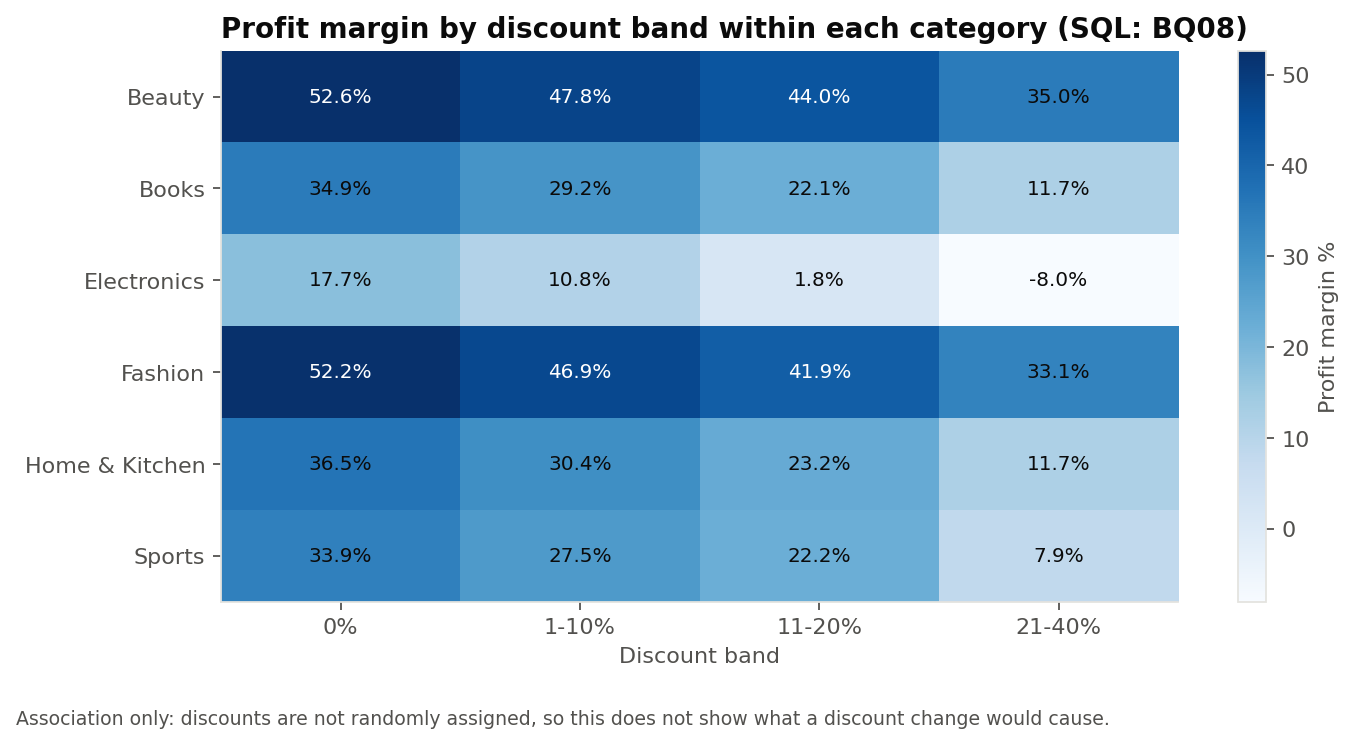

In [43]:
Image(str(FIG / "sql_discount_margin_by_category.png"))

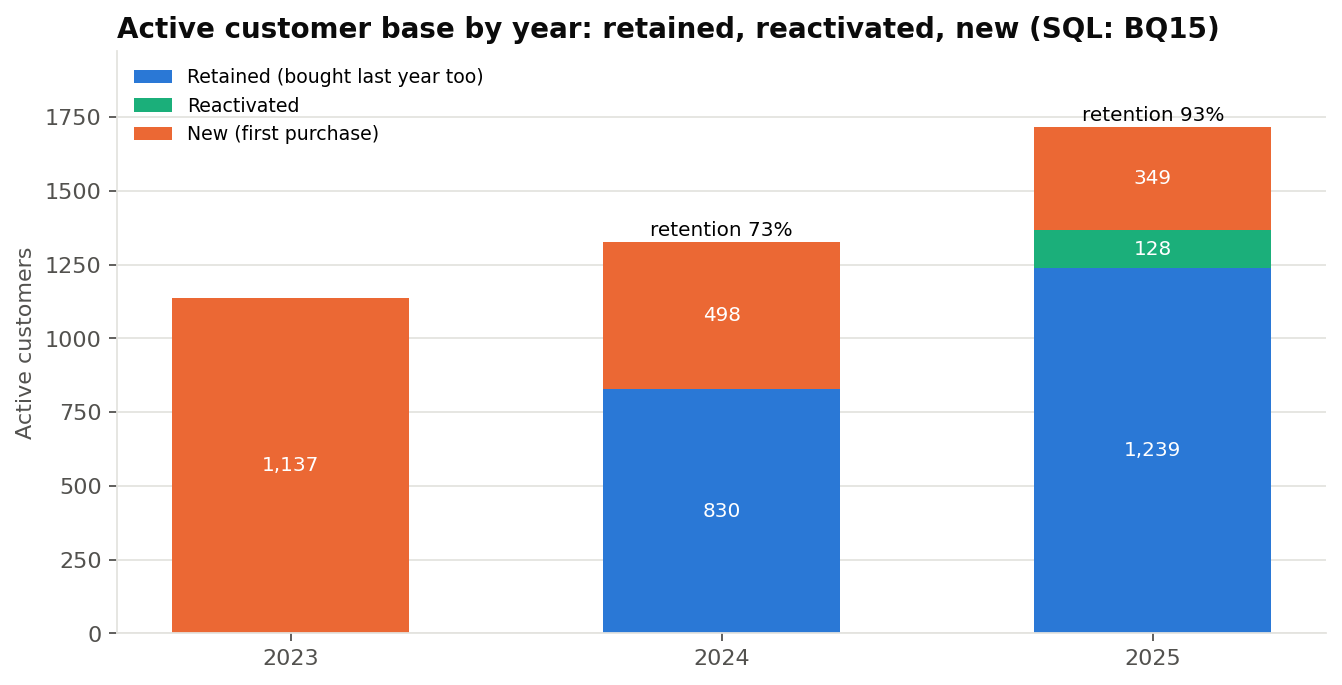

In [44]:
Image(str(FIG / "sql_customer_base_dynamics.png"))

- **Every question** has a documented purpose and a way to read the result, stored in the SQL file.
- **Result tables:** `outputs/tables/sql/BQ*.csv`.
- **Associations only:** the discount, payment-method and region comparisons are associations and do not show causes.

## 11. Advanced SQL techniques used

In [45]:
R['coverage']

,Technique,Queries_Using_It,Examples
0,INNER JOIN,18,"cust_acquired_by_year, cust_concentration_summary, cust_inactive, seg_rfm_summary, seg_value_activity_groups, seg_ml..."
1,LEFT JOIN,7,"cust_new_vs_existing, prod_profitability, reg_customers_without_orders, BQ01, BQ13, BQ15"
2,CASE WHEN,19,"cust_new_vs_existing, cust_frequency_distribution, cust_concentration_summary, cust_inactive, seg_rfm_vs_cluster, pr..."
3,CTE (WITH),27,"rev_by_year, rev_by_quarter, cust_top_revenue, cust_new_vs_existing, cust_acquired_by_year, cust_frequency_distribution"
4,Subquery,10,"cust_new_vs_existing, cust_inactive, seg_ml_cluster_summary, prod_top_revenue, prod_investigate, BQ03"
5,Window function,35,"rev_order_status, rev_by_year, rev_by_quarter, cust_top_revenue, cust_new_vs_existing, cust_frequency_distribution"
6,Ranking (RANK / ROW_NUMBER / NTILE),22,"cust_top_revenue, cust_new_vs_existing, cust_revenue_concentration, cust_concentration_summary, prod_category_perfor..."
7,Running total (window frame),4,"cust_revenue_concentration, time_monthly, time_ytd_running_total, BQ19"
8,Percentage contribution (SUM() OVER ()),18,"cust_top_revenue, cust_frequency_distribution, cust_revenue_concentration, seg_rfm_summary, seg_value_activity_group..."
9,LAG / LEAD,5,"rev_by_year, rev_by_quarter, time_monthly, BQ15, BQ17"


## 12. Key findings (computed by SQL)

In [46]:
R['findings']

,Area,Finding (computed by SQL),Source query
0,Revenue,"Delivered revenue ₹6.01 Cr, profit ₹1.40 Cr (23.35% margin), 12,212 orders, 1,984 customers, AOV ₹4,918.",rev_kpi_summary
1,Growth,"Revenue growth 2024: +51.4%, 2025: +37.7%; margin 22.65% -> 23.05% -> 23.90%.",rev_by_year
2,Customer concentration,Top 20% of customers = 64.33% of revenue; top 1% = 9.05%.,cust_concentration_summary
3,Repeat purchasing,Repeat customers are 89.4% of customers and 98.6% of revenue.,BQ12
4,Retention,"Retained / active last year: 2024: 73.0%, 2025: 93.3%; new customers per year 2023: 1,137, 2024: 498, 2025: 349.",BQ15
5,RFM segments,"Champions: 16.8% of customers, 53.8% of revenue; At Risk + Can't Lose Them: 18.4% of revenue.",seg_rfm_summary
6,ML clusters,"High-Value, Active: 18.35% of customers, 55.67% of revenue; Low-Value, Active: 22.83% of customers, 5.02% of revenue...",seg_ml_cluster_summary
7,Potentially at-risk value,52 high-historical-value customers have not bought for >= 180 days (lifetime revenue ₹26.51 L).,BQ06
8,Categories,Electronics: 50.1% of revenue at 10.8% margin; Fashion 36.8% of profit at 42.8% margin; highest margin Beauty (46.5%).,prod_category_performance
9,Products to investigate,"10 products flagged; high-revenue low-margin examples: Nova X7 Pro Smartphone 256GB, Nova X5 Smartphone 128GB, AeroB...","prod_investigate, BQ03"


## 13. Quality-control checklist

In [47]:
R['qc']

,Check,Evidence,Pass
0,Relational database created,data/customer_revenue_intelligence.db,True
1,Primary keys defined,11/11 tables,True
2,Foreign keys defined,9 foreign keys,True
3,Source data loaded successfully,11 tables,True
4,Row counts validated,Row counts area,True
5,SQL totals reconciled with Python,Totals area,True
6,"Keys, nulls and orphans checked",PK / FK / Nulls areas,True
7,"Cross-step consistency (Steps 5, 6, 7, 9)",Cross-step area,True
8,Customer analytics completed,10 queries,True
9,Product analytics completed,9 queries,True


In [48]:
con.close()